# Global Superstore Analytics: Predictive Modeling for Logistics & Profitability

## 1. Project Overview
This project aims to solve two critical business challenges for Global Superstore using Advanced Machine Learning (XGBoost):
1. **Shipping Cost Optimization:** Predicting and understanding the drivers of global shipping expenses.
2. **Profit Margin Maximization:** Identifying the "profit killers" and strategic levers to improve the bottom line.

---

## 1.1.  Data Understanding

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import plotly.express as px
from  plotly.subplots  import make_subplots
import plotly.graph_objects as go
import matplotlib.pyplot as plt  
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
import warnings

In [2]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',None)

In [3]:
df1= pd.read_csv('C:\data\BI_project_superstore\superstore.csv')
df1.head()

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,Order.Priority,Product.ID,Product.Name,Profit,Quantity,Region,Row.ID,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00.000,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


## 1.2. Data Preprocessing

In [4]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  object 
 1   City            51290 non-null  object 
 2   Country         51290 non-null  object 
 3   Customer.ID     51290 non-null  object 
 4   Customer.Name   51290 non-null  object 
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  object 
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  object 
 9   Order.ID        51290 non-null  object 
 10  Order.Priority  51290 non-null  object 
 11  Product.ID      51290 non-null  object 
 12  Product.Name    51290 non-null  object 
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  object 
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null 

In [5]:
df1.shape

(51290, 27)

In [6]:
df1.describe().T

,count,mean,std,min,25%,50%,75%,max
Discount,51290.0,0.142908,0.212280,0.000,0.00,0.00,0.20,0.850
记录数,51290.0,1.000000,0.000000,1.000,1.00,1.00,1.00,1.000
Profit,51290.0,28.610982,174.340972,-6599.978,0.00,9.24,36.81,8399.976
Quantity,51290.0,3.476545,2.278766,1.000,2.00,3.00,5.00,14.000
Row.ID,51290.0,25645.500000,14806.291990,1.000,12823.25,25645.50,38467.75,51290.000
Sales,51290.0,246.498440,487.567175,0.000,31.00,85.00,251.00,22638.000
Shipping.Cost,51290.0,26.375818,57.296810,0.002,2.61,7.79,24.45,933.570
Year,51290.0,2012.777208,1.098931,2011.000,2012.00,2013.00,2014.00,2014.000
weeknum,51290.0,31.287112,14.429795,1.000,20.00,33.00,44.00,53.000


In [7]:
print("\nMissing Values:")
print(df1.isnull().sum())


Missing Values:
Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64


In [8]:
#Check for duplicates
duplicates = df1.duplicated()
print(f"Duplicate rows found: {duplicates.sum()}")

Duplicate rows found: 0


In [9]:
columns_to_drop = ['记录数']
df = df1.drop(columns=columns_to_drop, axis=1)

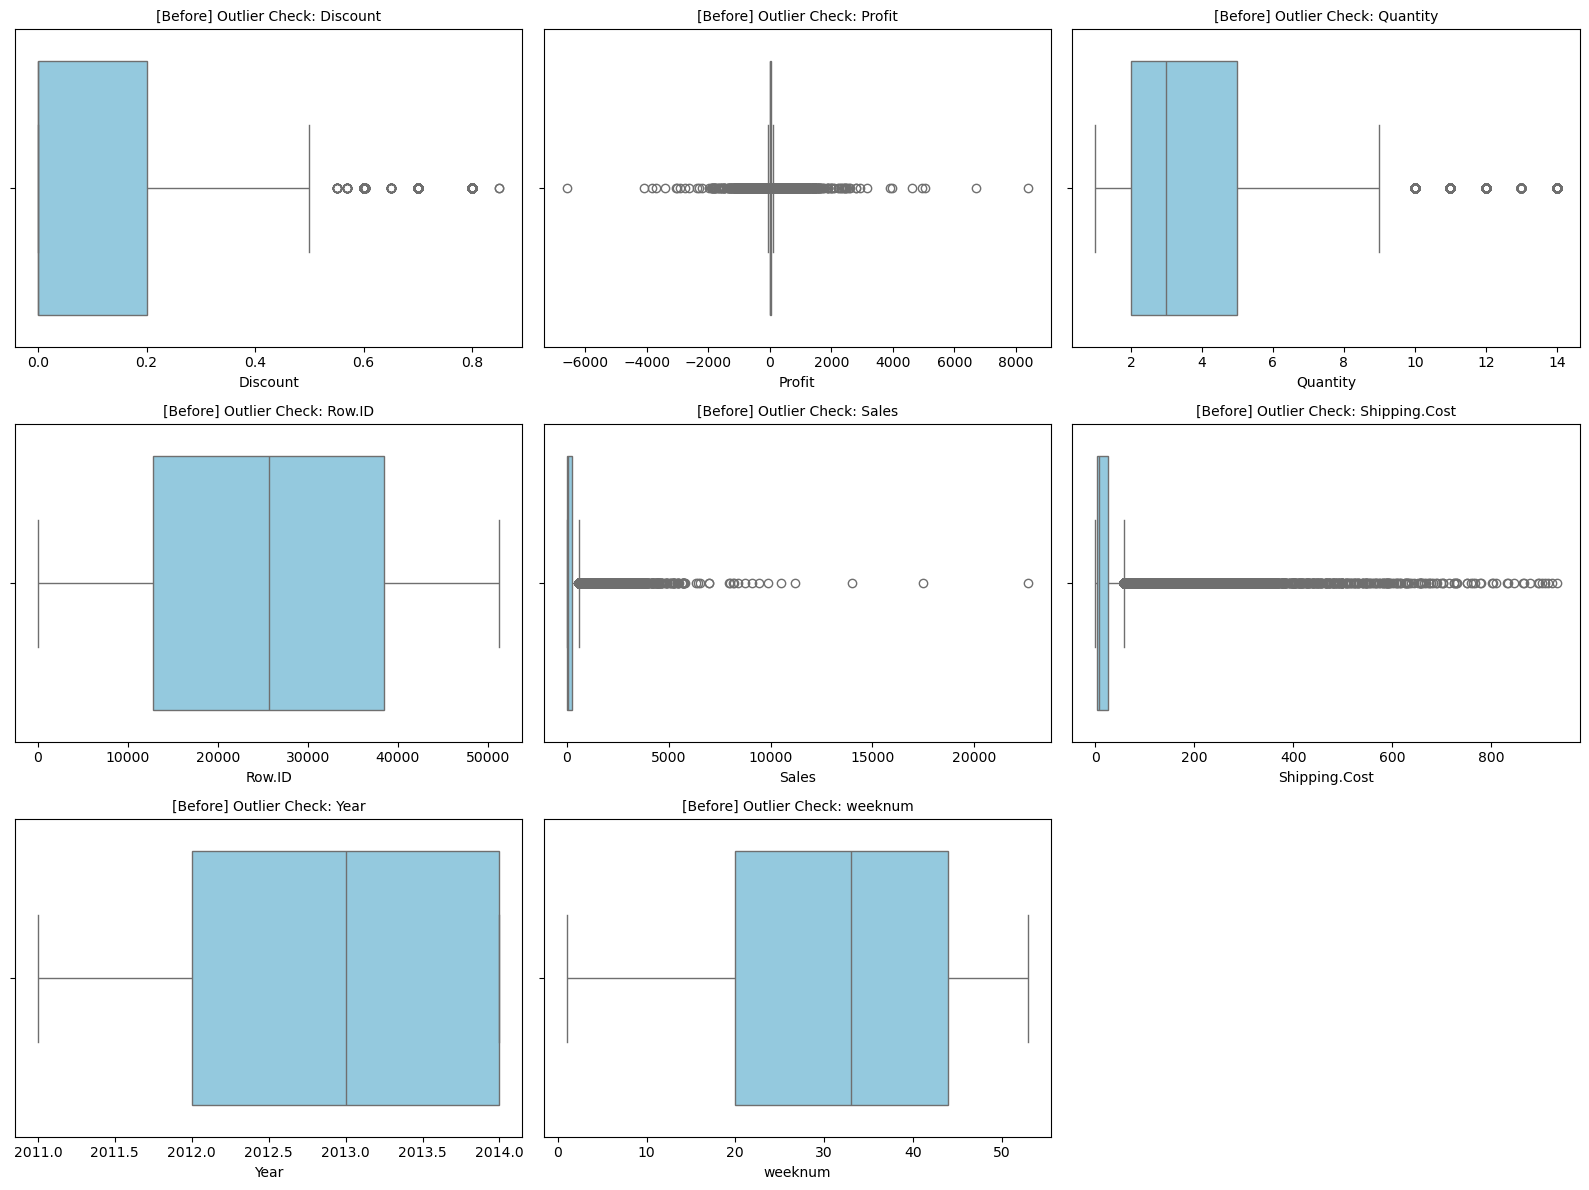

In [10]:
# Identify numeric columns
numeric_cols = df.select_dtypes(include='number').columns

# --- STEP 1: Visualize outliers before removal ---
cols = 3
rows = len(numeric_cols) // cols + (len(numeric_cols) % cols > 0)

plt.figure(figsize=(16, rows * 4))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'[Before] Outlier Check: {col}', fontsize=10)
    plt.tight_layout()

plt.show()

In [11]:
df[df['Sales'] == 0]

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,Order.Date,Order.ID,Order.Priority,Product.ID,Product.Name,Profit,Quantity,Region,Row.ID,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
46158,Office Supplies,Houston,United States,ZC-219104,Zuschuss Carroll,0.8,US,2014-06-20 00:00:00.000,US-2014-102288,Medium,OFF-AP-10002906,Hoover Replacement Belt for Commercial Guardsm...,-1.11,1,Central,35398,0,Consumer,2014-06-24 00:00:00.000,Standard Class,0.01,Texas,Appliances,2014,North America,25


discount = 0.8, profit = -1.11, Shipping.Cost = 0.01, Sales = 0

A **sales value of zero** is not realistic in a valid retail transaction and most likely results from the value **being rounded** down during data processing, which leads to the loss of essential revenue information and produces inconsistent profit values. Therefore, such rows should be removed.

#### 1.2.1 Check Profit < 0 

In [12]:
# Select only rows with negative profit
neg = df[df['Profit'] < 0].copy()

# 1. Total number of negative-profit rows
total_neg = len(neg)
print("Total rows with negative profit:", total_neg)

# 2. How many of those rows have a discount > 0
rows_with_discount = (neg['Discount'] > 0).sum()
print("Rows with negative profit AND a discount applied:", rows_with_discount)

# 3. Count occurrences of each discount level
discount_counts = neg['Discount'].value_counts().sort_index()
print("\nDiscount value counts for negative-profit rows:")
print(discount_counts)

# 4. Shipping cost summary
shipping_summary = neg['Shipping.Cost'].describe()
print("\nShipping cost summary for negative-profit rows:")
print(shipping_summary)

Total rows with negative profit: 12544
Rows with negative profit AND a discount applied: 12544

Discount value counts for negative-profit rows:
Discount
0.002      13
0.070      30
0.100     858
0.150     200
0.170     236
0.200    1027
0.202      25
0.250      98
0.270     197
0.300     281
0.320      27
0.350      84
0.370      49
0.400    2567
0.402      91
0.450     295
0.470     678
0.500    1616
0.550      10
0.570      12
0.600    2006
0.602      23
0.650      17
0.700    1786
0.800     316
0.850       2
Name: count, dtype: int64

Shipping cost summary for negative-profit rows:
count    12544.000000
mean        21.234778
std         47.381371
min          0.010000
25%          1.850000
50%          5.923000
75%         19.922500
max        923.630000
Name: Shipping.Cost, dtype: float64


Discount distribution:

- 40% discount → 2,567 rows
- 50% discount → 1,616 rows
- 60% discount → 2,006 rows
- 70% discount → 1,786 rows
- 80% discount → 316 rows
- 85% discount → 2 rows

Approximately 70% of all negative‐profit transactions occur at discount levels of 40% or higher, which substantially reduces sales revenue and leads to negative profit.

Negative profit values are expected given the patterns in the data. All **12,544 negative-profit transactions involve a discount**, and many of them include **very high discount levels (40–85%)**. At the same time, shipping costs remain significant, with a median of 5.92, a mean of 21.23, and a maximum reaching 923.63. The combination of heavy discounting and meaningful shipping cost naturally results in negative profit and represents normal retail behavior rather than data errors.

In [13]:
# Select all transactions with negative profit
neg = df[df['Profit'] < 0].copy()

# Keep only the relevant columns for analysis
neg_subset = neg[['Sales', 'Discount', 'Shipping.Cost', 'Profit']]

# Preview the first few rows of negative-profit transactions
neg_subset.head()

,Sales,Discount,Shipping.Cost,Profit
29009,684,0.15,100.32,-24.2715
29012,538,0.15,70.11,-19.0170
29018,95,0.15,5.53,-0.0495
29021,286,0.15,60.78,-6.7560
29024,1894,0.15,111.55,-111.4995


Even with a high **Sales** value of **1894**, a **15% Discount** and a **Shipping Cost of 111.55** lead to a **Profit of –111.50**.  
This shows that after applying the **Discount** and adding the **Shipping.Cost**, the final **Profit** becomes negative.  
Therefore, the **Profit** column represents the final (**net**) result, as both **Discount** and **Shipping.Cost** are already reflected in the value.

In [14]:
(df['Profit'] == 0).sum()

668

In [15]:
(df['Profit'].abs() < 0.01).sum()

689

In [16]:
zero_profit = df[df['Profit'] == 0].copy()
zero_profit[['Sales', 'Discount', 'Shipping.Cost', 'Profit']].head()

,Sales,Discount,Shipping.Cost,Profit
187,276,0.0,32.27,0.0
325,14,0.0,1.25,0.0
474,26,0.0,3.62,0.0
729,6,0.0,0.11,0.0
797,11,0.0,1.18,0.0


In [17]:
# --- PREPROCESSING ---
# 1. Convert to Datetime
df['Order.Date'] = pd.to_datetime(df['Order.Date'])
df['Ship.Date'] = pd.to_datetime(df['Ship.Date'])

# 2. NEW: Feature Engineering
df['Days_to_Ship'] = (df['Ship.Date'] - df['Order.Date']).dt.days
df['Order_Month'] = df['Order.Date'].dt.month

# 3. Drop invalid rows
df = df[df['Sales'] != 0]

# 4. Now define your X and y
X_profit = df[['Discount', 'Sales', 'Quantity', 'Shipping.Cost', 
               'Market', 'Category', 'Segment', 'Ship.Mode', 
               'Days_to_Ship', 'Order_Month']]

In [18]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Discount,51289.0,0.142895,0.0,0.0,0.0,0.2,0.85,0.212262
Order.Date,51289,2013-05-11 21:15:28.409600512,2011-01-01 00:00:00,2012-06-19 00:00:00,2013-07-08 00:00:00,2014-05-22 00:00:00,2014-12-31 00:00:00,NaN
Profit,51289.0,28.611562,-6599.978,0.0,9.24,36.81,8399.976,174.342622
Quantity,51289.0,3.476593,1.0,2.0,3.0,5.0,14.0,2.278762
Row.ID,51289.0,25645.309852,1.0,12823.0,25645.0,38468.0,51290.0,14806.37371
Sales,51289.0,246.503246,1.0,31.0,85.0,251.0,22638.0,487.570713
Ship.Date,51289,2013-05-15 20:31:21.947396352,2011-01-03 00:00:00,2012-06-23 00:00:00,2013-07-12 00:00:00,2014-05-26 00:00:00,2015-01-07 00:00:00,NaN
Shipping.Cost,51289.0,26.376332,0.002,2.61,7.79,24.45,933.57,57.29725
Year,51289.0,2012.777184,2011.0,2012.0,2013.0,2014.0,2014.0,1.098929
weeknum,51289.0,31.287235,1.0,20.0,33.0,44.0,53.0,14.429909


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51289 entries, 0 to 51289
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Category        51289 non-null  object        
 1   City            51289 non-null  object        
 2   Country         51289 non-null  object        
 3   Customer.ID     51289 non-null  object        
 4   Customer.Name   51289 non-null  object        
 5   Discount        51289 non-null  float64       
 6   Market          51289 non-null  object        
 7   Order.Date      51289 non-null  datetime64[ns]
 8   Order.ID        51289 non-null  object        
 9   Order.Priority  51289 non-null  object        
 10  Product.ID      51289 non-null  object        
 11  Product.Name    51289 non-null  object        
 12  Profit          51289 non-null  float64       
 13  Quantity        51289 non-null  int64         
 14  Region          51289 non-null  object        
 15  Row.ID 

### Download cleaned Data 

In [20]:
df_clean = df.copy()
df_clean.to_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/cleaned_dataset_superstore.csv", index=False, date_format="%d/%m/%Y %H:%M")

In [21]:
df_clean.head()

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,Order.Date,Order.ID,Order.Priority,Product.ID,Product.Name,Profit,Quantity,Region,Row.ID,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum,Days_to_Ship,Order_Month
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,2011-01-07,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-09,Second Class,4.37,California,Paper,2011,North America,2,2,1
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,2011-01-21,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,Standard Class,0.94,California,Paper,2011,North America,4,5,1
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,2011-08-05,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-09,Standard Class,1.81,California,Paper,2011,North America,32,4,8
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,2011-08-05,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-09,Standard Class,4.59,California,Paper,2011,North America,32,4,8
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,2011-09-29,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-03,Standard Class,1.32,California,Paper,2011,North America,40,4,9


### 1.2.2 Dataset Overview and Key Attributes 

In [22]:
# Separate column types
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
datetime_cols = df.select_dtypes(include=['datetime64[ns]']).columns
non_numeric_cols = df.select_dtypes(exclude=['int64', 'float64', 'datetime64[ns]']).columns

print("===== NUMERIC COLUMNS (Min–Max Range) =====")
for column in numeric_cols:
    col_min = df[column].min()
    col_max = df[column].max()
    print(f"{column}: Min = {col_min}, Max = {col_max}")

print("\n===== DATETIME COLUMNS (Earliest–Latest) =====")
for column in datetime_cols:
    col_min = df[column].min()
    col_max = df[column].max()
    print(f"{column}: Earliest = {col_min}, Latest = {col_max}")

print("\n===== NON-NUMERIC COLUMNS (Unique Values Count) =====")
for column in non_numeric_cols:
    unique_count = df[column].nunique()
    print(f"{column}: {unique_count} unique values")

===== NUMERIC COLUMNS (Min–Max Range) =====
Discount: Min = 0.0, Max = 0.85
Profit: Min = -6599.978, Max = 8399.976
Quantity: Min = 1, Max = 14
Row.ID: Min = 1, Max = 51290
Sales: Min = 1, Max = 22638
Shipping.Cost: Min = 0.002, Max = 933.57
Year: Min = 2011, Max = 2014
weeknum: Min = 1, Max = 53
Days_to_Ship: Min = 0, Max = 7

===== DATETIME COLUMNS (Earliest–Latest) =====
Order.Date: Earliest = 2011-01-01 00:00:00, Latest = 2014-12-31 00:00:00
Ship.Date: Earliest = 2011-01-03 00:00:00, Latest = 2015-01-07 00:00:00

===== NON-NUMERIC COLUMNS (Unique Values Count) =====
Category: 3 unique values
City: 3636 unique values
Country: 147 unique values
Customer.ID: 4873 unique values
Customer.Name: 795 unique values
Market: 7 unique values
Order.ID: 25035 unique values
Order.Priority: 4 unique values
Product.ID: 10292 unique values
Product.Name: 3788 unique values
Region: 13 unique values
Segment: 3 unique values
Ship.Mode: 4 unique values
State: 1094 unique values
Sub.Category: 17 unique va

#### 1.2.3 Unique Values Checking

In [23]:
# select object/category columns
non_numeric_cols = df.select_dtypes(include=['object'])

# display 3 sample values for each selected column
for col in non_numeric_cols:
    print(f"\n{col} ({df[col].nunique()} unique values):")

    # unique values
    uniques = df[col].unique()
    print("All Unique Values:", uniques)

    # sample 3 values
    sample_vals = df[col].dropna().unique()[:3]   # first 3 unique values
    print("Sample Values:", sample_vals)


Category (3 unique values):
All Unique Values: ['Office Supplies' 'Technology' 'Furniture']
Sample Values: ['Office Supplies' 'Technology' 'Furniture']

City (3636 unique values):
All Unique Values: ['Los Angeles' 'San Francisco' 'San Diego' ... 'Ontario' 'Whittier'
 'Redwood City']
Sample Values: ['Los Angeles' 'San Francisco' 'San Diego']

Country (147 unique values):
All Unique Values: ['United States' 'France' 'Germany' 'El Salvador' 'Guatemala' 'Austria'
 'Nicaragua' 'Belgium' 'Switzerland' 'Italy' 'South Africa' 'India'
 'Hong Kong' 'Democratic Republic of the Congo' 'Cuba' 'United Kingdom'
 'Spain' 'Russia' 'China' 'Niger' 'Qatar' 'New Zealand' 'Mexico'
 'Malaysia' 'Poland' 'Madagascar' 'Iraq' 'Brazil' 'Colombia'
 'Saudi Arabia' 'Egypt' 'Iran' 'Ukraine' 'Japan' 'Morocco' 'Cameroon'
 'Chile' 'Ghana' 'Trinidad and Tobago' 'Canada' 'Chad' 'Kenya'
 'Bangladesh' 'Bulgaria' 'Djibouti' 'Uruguay' 'Singapore' 'Czech Republic'
 'Zambia' 'Bolivia' 'Angola' 'Australia' 'Tanzania' 'Norway'


In [24]:
# select object/category columns
non_numeric_cols = df.select_dtypes(include=['object'])

# filter columns with fewer than 15 unique values
cols_under_15 = [col for col in non_numeric_cols if df[col].nunique() < 15]

# display the unique values for each selected column
for col in cols_under_15:
    print(f"\n{col} ({df[col].nunique()} unique values):")
    print(df[col].unique())


Category (3 unique values):
['Office Supplies' 'Technology' 'Furniture']

Market (7 unique values):
['US' 'EU' 'LATAM' 'Africa' 'APAC' 'EMEA' 'Canada']

Order.Priority (4 unique values):
['High' 'Medium' 'Critical' 'Low']

Region (13 unique values):
['West' 'East' 'South' 'Central' 'Africa' 'Central Asia' 'North Asia'
 'Caribbean' 'North' 'EMEA' 'Oceania' 'Southeast Asia' 'Canada']

Segment (3 unique values):
['Consumer' 'Home Office' 'Corporate']

Ship.Mode (4 unique values):
['Second Class' 'Standard Class' 'Same Day' 'First Class']

Market2 (6 unique values):
['North America' 'EU' 'LATAM' 'Africa' 'APAC' 'EMEA']


# 2. Exploratory Data Analysis

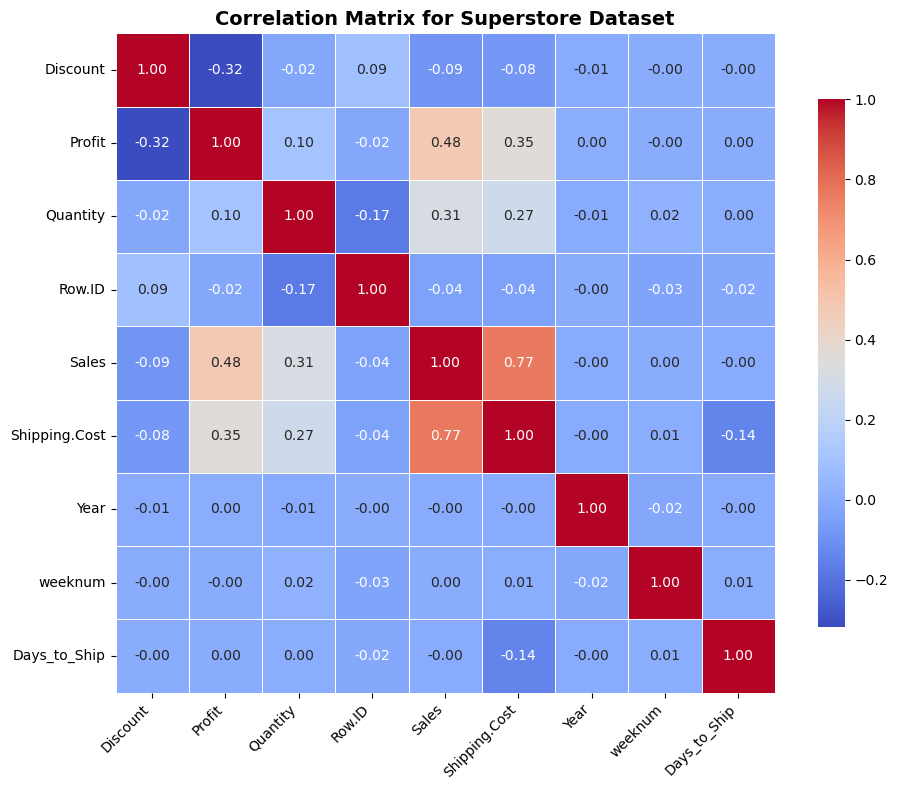

In [25]:
# ---------------------------------------------
# 1. Select only numerical columns for correlation
# ---------------------------------------------
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Compute the correlation matrix
corr_matrix = df[numeric_cols].corr()

# ---------------------------------------------
# 2. Plot an enhanced correlation heatmap
# ---------------------------------------------
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,         # display correlation values
    fmt=".2f",          # number formatting
    cmap="coolwarm",    # color palette
    linewidths=0.5,     # thin lines between cells
    square=True,        # square cells for neatness
    cbar_kws={"shrink": 0.8}  # smaller color bar
)

plt.title("Correlation Matrix for Superstore Dataset", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 2.1. Sales and Product Categories

In [26]:
df['Category'].unique()

array(['Office Supplies', 'Technology', 'Furniture'], dtype=object)

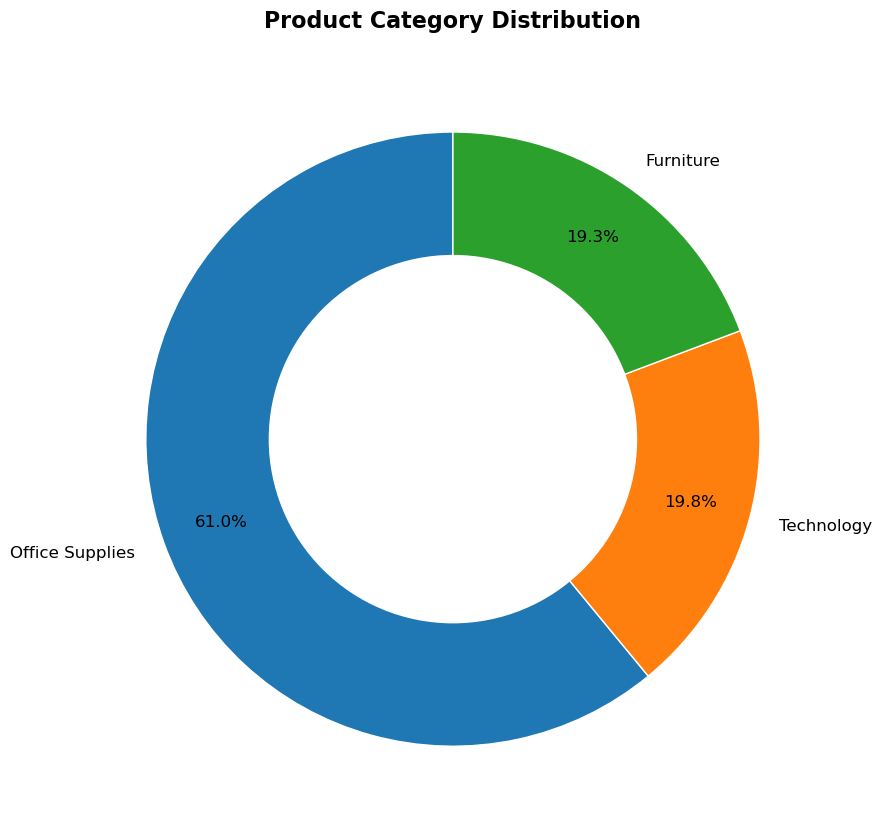

In [27]:
# Count category frequency
category_counts = df['Category'].value_counts()

# Plot pie chart with improved styling
plt.figure(figsize=(9, 9))
plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.8,
    textprops={'fontsize': 12},
    wedgeprops={'edgecolor': 'white', 'linewidth': 1}
)

# Add custom title with better aesthetics
plt.title('Product Category Distribution', 
          fontsize=16, fontweight='bold', pad=20)

# Add a white circle in the middle to create a donut-style chart (more modern)
centre_circle = plt.Circle((0, 0), 0.60, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.tight_layout()
plt.show()

In [28]:
total_sales = df['Sales'].sum()
print(total_sales)

12642905


In [29]:
total_profit = df['Profit'].sum()
print(total_profit)

1467458.40128


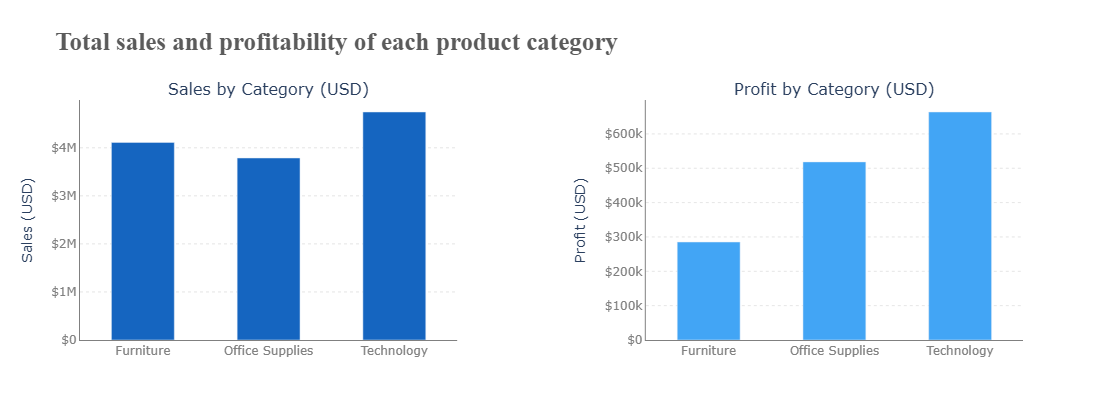

In [30]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

category_sales = df.groupby('Category').agg({'Sales':'sum','Profit':'sum'})

def Display_Sales_category():
    fig = make_subplots(
        rows=1, 
        cols=2, 
        subplot_titles=("Sales by Category (USD)", "Profit by Category (USD)"),
        horizontal_spacing=0.20
    )

    # --- Sales Chart ---
    fig.add_trace(
        go.Bar(
            x=category_sales.index,
            y=category_sales['Sales'],
            marker_color="#1565c0",
            name="Sales"
        ), row=1, col=1
    )

    # --- Profit Chart (lighter blue) ---
    fig.add_trace(
        go.Bar(
            x=category_sales.index,
            y=category_sales['Profit'],
            marker_color="#42a5f5",
            name="Profit"
        ), row=1, col=2
    )

    fig.update_layout(
        title_text='<b>Total sales and profitability of each product category</b>',
        title_font_size=25,
        title_font_family="Liberation Serif",
        title_font_color="#5b5b5b",
        plot_bgcolor='white',
        bargap=0.5,
        width=950,
        height=420,
        showlegend=False
    )

    # --- Y-Axis (kept for clarity) ---
    fig.update_yaxes(
        title_text="Sales (USD)",
        row=1, col=1,
        showgrid=True,
        gridwidth=0.6,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray'),
        showline=True,
        linewidth=1,
        linecolor='gray',
        tickprefix="$",
        separatethousands=True
    )

    fig.update_yaxes(
        title_text="Profit (USD)",
        row=1, col=2,
        showgrid=True,
        gridwidth=0.6,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray'),
        showline=True,
        linewidth=1,
        linecolor='gray',
        tickprefix="$",
        separatethousands=True
    )

    # --- X-Axis (label removed for cleaner visual) ---
    fig.update_xaxes(
        tickfont=dict(color='gray'),
        showline=True,
        linewidth=1,
        linecolor='gray'
    )

    fig.show()

Display_Sales_category()

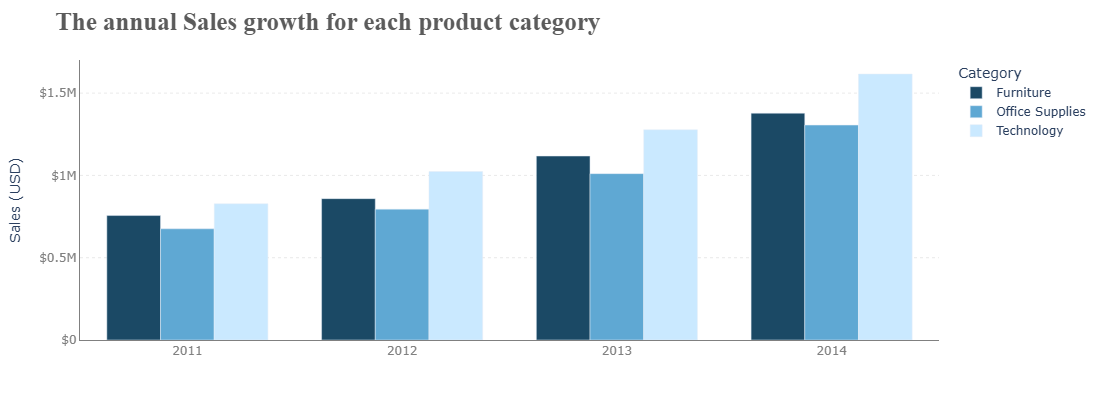

In [31]:
growth_cate_year = pd.pivot_table(
    data=df,
    index='Year',
    columns='Category',
    values=['Sales', 'Profit'],
    aggfunc=['sum']
)

def Display_Sales_cate_year():
    data = growth_cate_year['sum']['Sales']
    
    fig4 = px.bar(
        data,
        x=data.index,
        y=data.columns,
        barmode='group',
        color_discrete_sequence=['#1B4965', '#5FA8D3', '#CAE9FF']   # warna tetap: dark → medium → light
    )
    
    fig4.update_layout(
        title_text="<b>The annual Sales growth for each product category</b>",
        title_font_size=25,
        title_font_family="Liberation Serif",
        title_font_color="#5b5b5b",
        xaxis_title='',          
        yaxis_title='',          
        plot_bgcolor='white',
        bargap=0.25,
        width=850,
        height=420,
        showlegend=True
    )
    
    # --- Y-axis professional formatting ---
    fig4.update_yaxes(
        title_text="Sales (USD)",           # tetap memberi konteks penting
        showgrid=True,
        gridwidth=0.5,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray'),
        showline=True,
        linewidth=1,
        linecolor='gray',
        tickprefix="$",
        separatethousands=True
    )
    
    # --- X-axis clean formatting ---
    fig4.update_xaxes(
        tickfont=dict(color='gray'),
        showline=True,
        linewidth=1,
        linecolor='gray'
    )
    
    fig4.show()

Display_Sales_cate_year()


## 2.2 Customer Analysis

In [32]:
customer_sales = df.groupby('Segment').agg({'Sales':['sum','mean']})

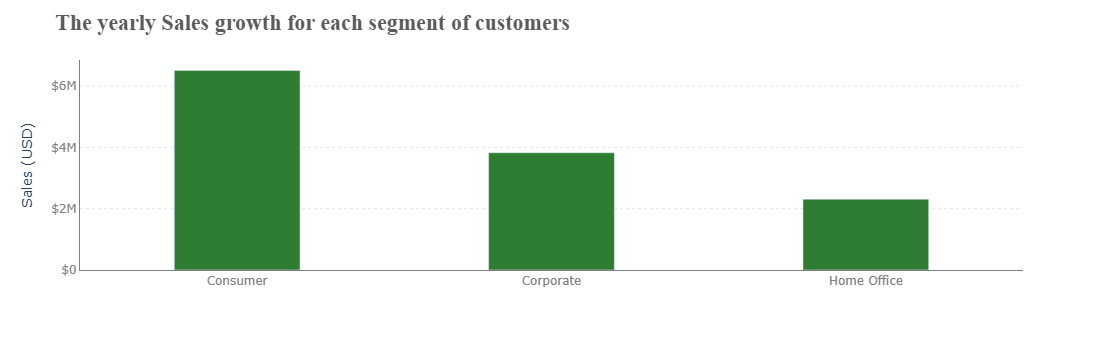

In [33]:
import plotly.express as px

def Display_sales_segment():
    data = customer_sales['Sales']['sum']

    fig4 = px.bar(
        data,
        x=data.index,
        y=data.values,
        color_discrete_sequence=["#2e7d32"]  # deep green
    )

    fig4.update_layout(
        title_text=f"<b>The yearly Sales growth for each segment of customers</b>",
        title_font_size=22,
        title_font_family="Liberation Serif",
        title_font_color="#5b5b5b",
        xaxis_title='',
        yaxis_title='Sales (USD)',
        plot_bgcolor='white',
        bargap=0.6,
        height=350,
        width=600,
    )

    # Format Y-axis: no trailing .0 (1M instead of 1.0M)
    fig4.update_yaxes(
        tickformat='$,.2~s',      # ← removes .0 → 1M, 2M, 1.5M
        showgrid=True,
        gridwidth=0.6,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray'),
        showline=True,
        linewidth=1,
        linecolor='gray'
    )

    fig4.update_xaxes(
        tickfont=dict(color='gray'),
        showline=True,
        linewidth=1,
        linecolor='gray'
    )

    fig4.show()

Display_sales_segment()

In [34]:
# CROSSCHECK
df['Order.Date'] = pd.to_datetime(df['Order.Date'])

# Filter tahun 2014
df_2014 = df[df['Order.Date'].dt.year == 2014]

# Hitung total unique customer
total_customers_2014 = df_2014['Customer.ID'].nunique()
print('total customer 2014: ', total_customers_2014)

total customer 2014:  3948


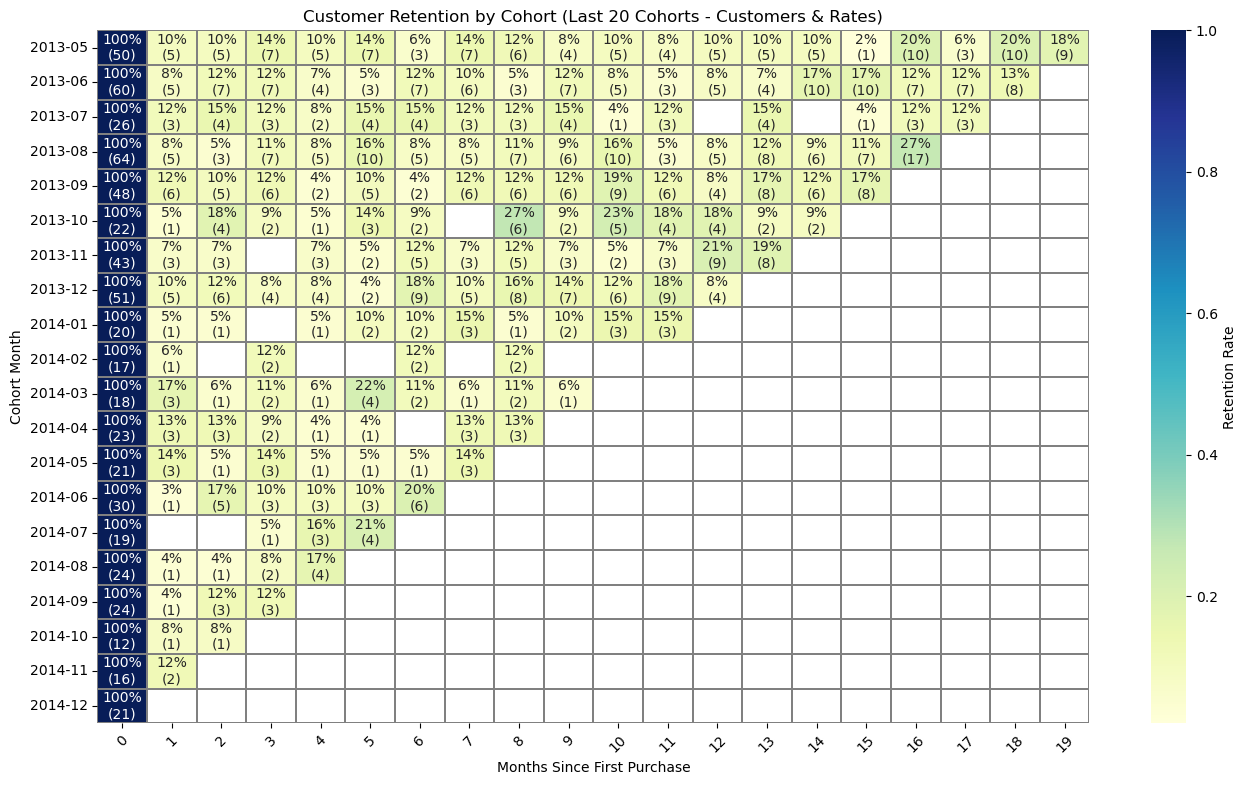

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- PREPROCESSING ---
df['OrderMonth'] = df['Order.Date'].dt.to_period('M')

# --- DEFINING COHORT MONTH (FIRST PURCHASE MONTH) ---
df['CohortMonth'] = df.groupby('Customer.ID')['OrderMonth'].transform('min')

# --- GROUPING CUSTOMER COUNTS ---
cohort = (
    df.groupby(['CohortMonth', 'OrderMonth'])['Customer.ID']
    .nunique()
    .reset_index()
)

# --- CALCULATING PERIOD (MONTH OFFSET) ---
cohort['Period'] = (cohort['OrderMonth'] - cohort['CohortMonth']).apply(lambda x: x.n)

# --- CREATING COHORT PIVOT: CUSTOMER COUNT ---
cohort_pivot = cohort.pivot_table(
    index='CohortMonth',
    columns='Period',
    values='Customer.ID'
)

# --- RETENTION MATRIX ---
cohort_retention = cohort_pivot.divide(cohort_pivot.iloc[:, 0], axis=0)

# --- LAST 20 COHORTS ---
last20_ret = cohort_retention.tail(20)
last20_cnt = cohort_pivot.tail(20)

# --- DROP COLUMNS THAT ARE COMPLETELY EMPTY ---
clean_ret = last20_ret.dropna(axis=1, how='all')
clean_cnt = last20_cnt[clean_ret.columns]

# --- CREATE ANNOTATION: "xx% (n)" ---
annot = clean_ret.copy()

for i in clean_ret.index:
    for j in clean_ret.columns:
        pct = clean_ret.loc[i, j]
        cnt = clean_cnt.loc[i, j]
        if pd.isna(pct) or pd.isna(cnt):
            annot.loc[i, j] = ""
        else:
            annot.loc[i, j] = f"{pct:.0%}\n({int(cnt)})"

# --- PLOTTING HEATMAP ---
plt.figure(figsize=(16, 9))
ax = sns.heatmap(
    clean_ret,
    cmap="YlGnBu",
    annot=annot,
    fmt="",
    linewidths=0.3,
    linecolor='gray',
    cbar_kws={'label': 'Retention Rate'}
)

plt.title("Customer Retention by Cohort (Last 20 Cohorts - Customers & Rates)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

In [36]:
# Ensure datetime format
df['Order.Date'] = pd.to_datetime(df['Order.Date'])
df['OrderMonth'] = df['Order.Date'].dt.to_period('M')

# Cohort month = first purchase month per customer
first_purchase = df.groupby('Customer.ID')['OrderMonth'].min()

# Convert to DataFrame
cohort_size = first_purchase.value_counts().sort_index().rename("NewCustomers").to_frame()

# Filter 2011–2014 only
cohort_2011_2014 = cohort_size[(cohort_size.index >= '2011-01') & (cohort_size.index <= '2014-12')]

# Add a year column
cohort_2011_2014['Year'] = cohort_2011_2014.index.year

# Group by year to get total new customers per year
cohort_by_year = cohort_2011_2014.groupby('Year')['NewCustomers'].sum().to_frame()

# Calculate grand total
grand_total = cohort_by_year['NewCustomers'].sum()

print("New Customers Per Year (2011–2014):\n")
print(cohort_by_year)

print("\nGrand Total New Customers (2011–2014):", grand_total)

New Customers Per Year (2011–2014):

      NewCustomers
Year              
2011          2890
2012          1172
2013           566
2014           245

Grand Total New Customers (2011–2014): 4873


In [37]:
total_unique_customers = df['Customer.ID'].nunique()
total_unique_customers

4873

## 2.3 Order Placement and Trends

In [38]:
df['Order.ID'].nunique()

25035

In [39]:
Date_trend = df.groupby('Order.Date').agg({'Sales':'sum'})
Date_trend_resampling = Date_trend.resample('7d').mean()

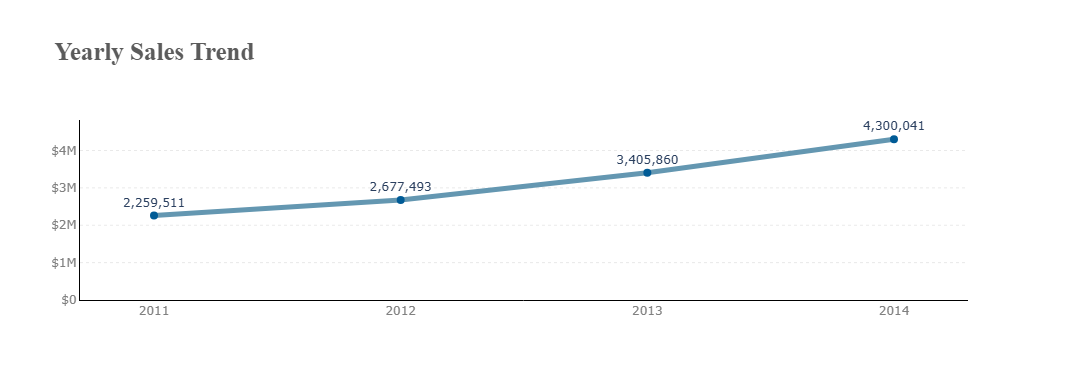

In [40]:
# 1. Define the dataframe used by the chart
date_sale = df.groupby('Year', as_index=False)['Sales'].sum()

# 2. function
def Display_Sales_year():
    fig4 = px.line(
        date_sale,
        x='Year',
        y='Sales',
        markers=True,
        color_discrete_sequence=['#6497b1'],
        text=date_sale['Sales'].apply(lambda x: f'{x:,}')
    )

    fig4.update_traces(
        line=dict(width=5),
        marker=dict(size=8, color='#005b96'),
        textposition='top center',
        textfont=dict(size=12)
    )

    max_sales = date_sale['Sales'].max()
    fig4.update_yaxes(
        range=[0, max_sales * 1.12],
        tickformat="$,.2~s",
        showgrid=True,
        gridwidth=0.5,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray'),
        showline=True,
        linecolor='black',
        linewidth=1
    )

    fig4.update_xaxes(
        tickfont=dict(color='gray'),
        dtick=1,
        showline=True,
        linecolor='black',
        linewidth=1,
        range=[date_sale['Year'].min() - 0.3, date_sale['Year'].max() + 0.3]
    )

    fig4.update_layout(
        title_text="<b>Yearly Sales Trend</b>",
        title_font_size=25,
        title_font_family="Liberation Serif",
        title_font_color="#5b5b5b",
        xaxis_title='',
        yaxis_title='',
        plot_bgcolor='white',
        width=800,
        height=380,
        margin=dict(l=80, r=120, t=120, b=80)
    )

    fig4.show()

# 3. Call function
Display_Sales_year()

## 2.4 Market

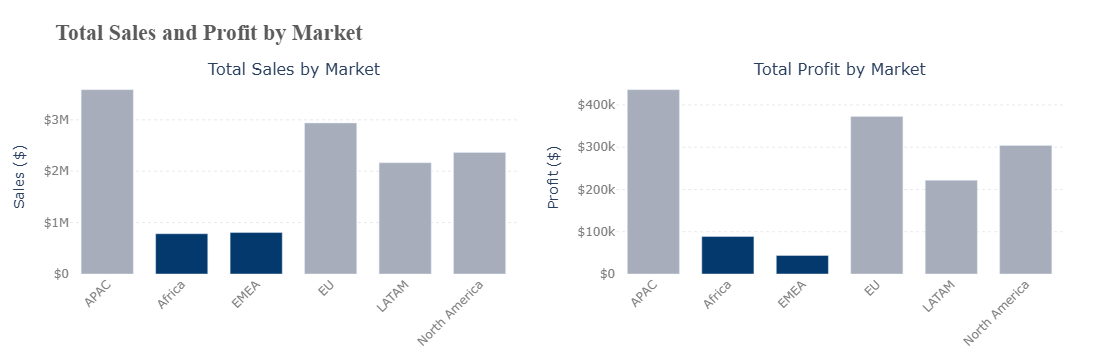

In [41]:
# Aggregate TOTAL Sales and Profit per Market
market_group = (
    df.groupby('Market2', as_index=False)
      .agg({'Sales': 'sum', 'Profit': 'sum'})
)

def Display_market_sale_profit():

    # -----------------------------------
    # Identify 2 lowest markets (Sales)
    # -----------------------------------
    lowest_sales_markets = market_group.nsmallest(2, 'Sales')['Market2'].tolist()

    # Color mapping for Sales chart
    colors_sales = [
        '#03396c' if m in lowest_sales_markets else '#a7adba'
        for m in market_group['Market2']
    ]

    # -----------------------------------
    # Identify 2 lowest markets (Profit)
    # -----------------------------------
    lowest_profit_markets = market_group.nsmallest(2, 'Profit')['Market2'].tolist()

    # Color mapping for Profit chart
    colors_profit = [
        '#03396c' if m in lowest_profit_markets else '#a7adba'
        for m in market_group['Market2']
    ]

    # -----------------------------------
    # Create subplots
    # -----------------------------------
    fig = make_subplots(
        rows=1,
        cols=2,
        subplot_titles=("Total Sales by Market", "Total Profit by Market")
    )

    # Left: Sales
    fig.add_trace(
        go.Bar(
            x=market_group['Market2'],
            y=market_group['Sales'],
            name='Sales',
            marker=dict(color=colors_sales)
        ),
        row=1, col=1
    )

    # Right: Profit
    fig.add_trace(
        go.Bar(
            x=market_group['Market2'],
            y=market_group['Profit'],
            name='Profit',
            marker=dict(color=colors_profit)
        ),
        row=1, col=2
    )

    # -----------------------------------
    # Layout Formatting
    # -----------------------------------
    fig.update_layout(
        title_text="<b>Total Sales and Profit by Market</b>",
        title_font_size=22,
        title_font_family="Liberation Serif",
        title_font_color="#5b5b5b",
        plot_bgcolor='white',
        bargap=0.3,
        width=1000,
        height=360,
        margin=dict(l=70, r=40, t=80, b=80),
        showlegend=False
    )

    # Y-axis formatting
    fig.update_yaxes(
        title_text="Sales ($)",
        tickformat="$,.2~s",
        showgrid=True,
        gridwidth=0.5,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray'),
        row=1, col=1
    )
    fig.update_yaxes(
        title_text="Profit ($)",
        tickformat="$,.2~s",
        showgrid=True,
        gridwidth=0.5,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray'),
        row=1, col=2
    )

    # X-axis label angles
    fig.update_xaxes(tickangle=-45, tickfont=dict(color='gray'), row=1, col=1)
    fig.update_xaxes(tickangle=-45, tickfont=dict(color='gray'), row=1, col=2)

    fig.show()

Display_market_sale_profit()


In [42]:
# Check underlying numbers for Sales & Profit by Region
region_metrics = df.groupby('Market', as_index=False)[['Sales', 'Profit']].sum()
print(region_metrics)

   Market    Sales        Profit
0    APAC  3585833  436000.04900
1  Africa   783776   88871.63100
2  Canada    66932   17817.39000
3    EMEA   806184   43897.97100
4      EU  2938139  372829.74150
5   LATAM  2164687  221643.48708
6      US  2297354  286398.13170


In [43]:
def avg_shipping_days_per_mode(regions=None):
    if regions is not None:
        df_plot = df[df["Market"].isin(regions)].copy()
    else:
        df_plot = df.copy()

    df_plot['Shipping_Days'] = (
        df_plot['Ship.Date'] - df_plot['Order.Date']
    ).dt.days

    return (
        df_plot.groupby('Ship.Mode')['Shipping_Days']
               .mean()
               .sort_values()
               .reset_index(name='Avg_Shipping_Days')
    )

avg_shipping_days_per_mode()

,Ship.Mode,Avg_Shipping_Days
0,Same Day,0.037394
1,First Class,2.181746
2,Second Class,3.230187
3,Standard Class,4.998050


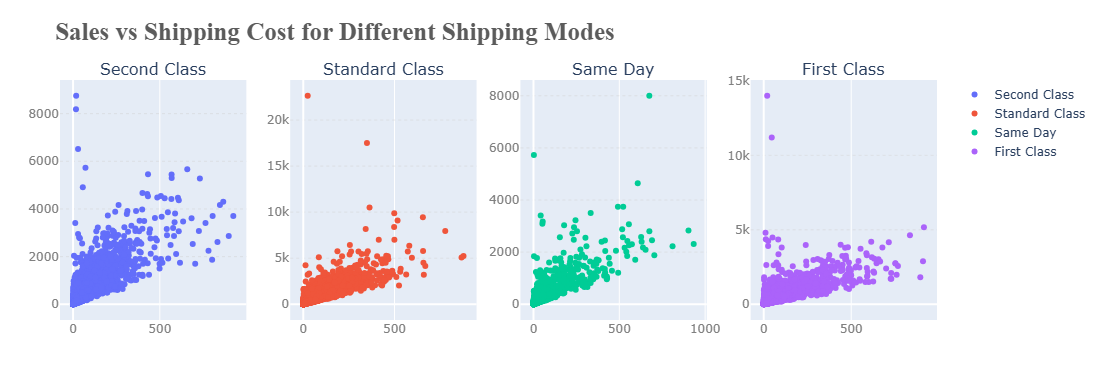

In [44]:
def Display_Sales_shipMode(regions=None):
    """
    Display scatter plots of Sales vs Shipping Cost for each Shipping Mode,
    with optional filtering by region (Market).
    
    Parameters:
    - regions: list of region names (e.g. ["Africa", "EMEA"])
               If None → uses all regions.
    """

    # --- FILTER DATA IF REGIONS ARE PROVIDED ---
    if regions is not None:
        df_plot = df[df["Market"].isin(regions)]
        title_suffix = f" (Filtered: {', '.join(regions)})"
    else:
        df_plot = df.copy()
        title_suffix = ""

    shipping_modes = df_plot['Ship.Mode'].unique()

    # Create subplots dynamically
    fig = make_subplots(
        rows=1,
        cols=len(shipping_modes),
        subplot_titles=shipping_modes,
        horizontal_spacing=0.05
    )

    # Plot each shipping mode
    for i, mode in enumerate(shipping_modes):
        mode_data = df_plot[df_plot['Ship.Mode'] == mode]

        fig.add_trace(
            go.Scatter(
                x=mode_data['Shipping.Cost'],
                y=mode_data['Sales'],
                mode='markers',
                name=mode
            ),
            row=1,
            col=i+1
        )

    # Layout formatting
    fig.update_layout(
        title=f"<b>Sales vs Shipping Cost for Different Shipping Modes{title_suffix}</b>",
        title_font_size=25,
        title_font_family="Liberation Serif",
        title_font_color="#5b5b5b",
        width=1300,
        height=380,
        margin=dict(l=60, r=40, t=80, b=60)
    )

    fig.update_yaxes(
        showgrid=True,
        gridwidth=0.5,
        gridcolor='lightgray',
        griddash='dot',
        tickfont=dict(color='gray')
    )
    fig.update_xaxes(tickfont=dict(color='gray'))

    fig.show()
Display_Sales_shipMode()


In [45]:
import plotly.graph_objects as go

# Aggregate by market
market_summary = (
    df.groupby("Market2", as_index=False)
      .agg(Avg_Shipping_Cost=("Shipping.Cost", "mean"),
           Total_Profit=("Profit", "sum"))
      .sort_values("Market2")
)

fig = go.Figure()

# Bars: Total Profit
fig.add_bar(
    x=market_summary["Market2"],
    y=market_summary["Total_Profit"],
    name="Total Profit",
    marker_color="#c8ccd4"
)

# Line: Avg Shipping Cost (secondary y-axis)
fig.add_scatter(
    x=market_summary["Market2"],
    y=market_summary["Avg_Shipping_Cost"],
    name="Avg Shipping Cost",
    mode="lines+markers",
    line=dict(color="#005b96", width=4),
    marker=dict(size=8),
    yaxis="y2"
)

fig.update_layout(
    title="<b>Profit vs Shipping Cost by Market</b>",
    width=1100,
    height=520,
    plot_bgcolor="white",
    margin=dict(l=60, r=40, t=70, b=110),
    legend=dict(
        orientation="h",
        x=0.5, y=-0.25,
        xanchor="center", yanchor="top"
    ),
    xaxis=dict(
        tickangle=45,
        showgrid=False,
        zeroline=False
    ),
    yaxis=dict(
        title="Total Profit ($)",
        tickformat="$,.2~s",
        showgrid=False,
        zeroline=False
    ),
    yaxis2=dict(
        overlaying="y",
        side="right",
        title="Avg Shipping Cost ($)",
        tickformat="$,.0f",
        range=[0, 50],
        showgrid=False,
        zeroline=False
    )
)

fig.show()

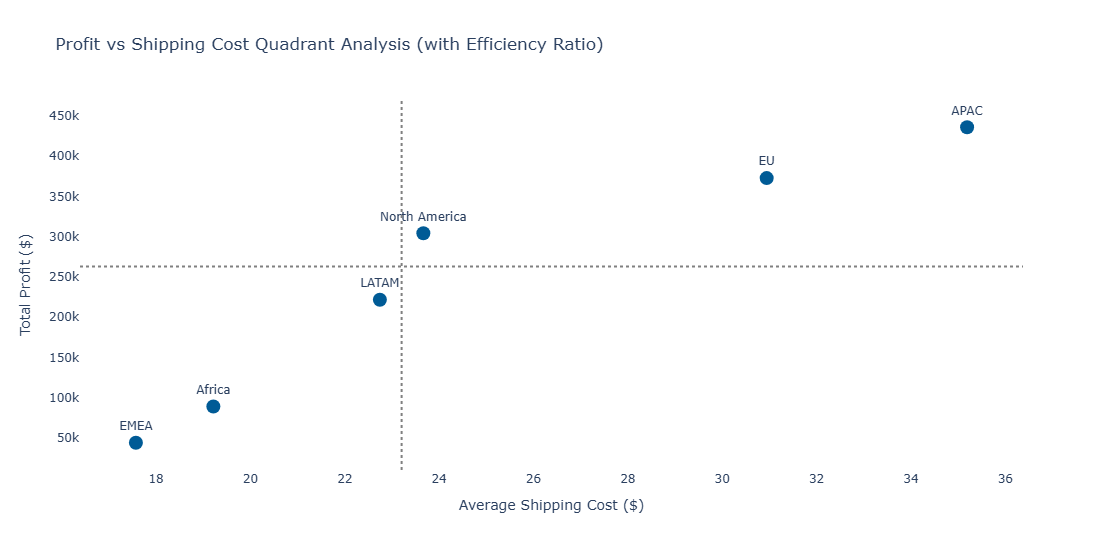

,Market2,Avg_Shipping_Cost,Total_Profit,Cost_Profit_Ratio
2,EMEA,17.573221,43897.97100,0.000400
1,Africa,19.215058,88871.63100,0.000216
4,LATAM,22.744668,221643.48708,0.000103
3,EU,30.942235,372829.74150,0.000083
0,APAC,35.190430,436000.04900,0.000081
5,North America,23.665743,304215.52170,0.000078


In [46]:
# --- 1. Prepare data ---
market_summary = df.groupby("Market2", as_index=False).agg(
    Avg_Shipping_Cost=("Shipping.Cost", "mean"),
    Total_Profit=("Profit", "sum")
)

# Add efficiency ratio
market_summary["Cost_Profit_Ratio"] = (
    market_summary["Avg_Shipping_Cost"] / market_summary["Total_Profit"]
)

# -- midpoints for quadrant ---
mid_cost = market_summary["Avg_Shipping_Cost"].median()
mid_profit = market_summary["Total_Profit"].median()

# --- 2. Quadrant scatter plot ---
fig = px.scatter(
    market_summary,
    x="Avg_Shipping_Cost",
    y="Total_Profit",
    text="Market2",
    size_max=20,
    title="Profit vs Shipping Cost Quadrant Analysis (with Efficiency Ratio)",
)

# Add quadrant lines
fig.add_hline(y=mid_profit, line_dash="dot", line_color="gray")
fig.add_vline(x=mid_cost, line_dash="dot", line_color="gray")

# Formatting
fig.update_traces(marker=dict(size=14, color="#005b96"))
fig.update_traces(textposition="top center")

fig.update_layout(
    width=900,
    height=550,
    xaxis_title="Average Shipping Cost ($)",
    yaxis_title="Total Profit ($)",
    plot_bgcolor="white"
)

fig.show()

# --- 3. Display ratio table (sorted by inefficiency) ---
ratio_table = (
    market_summary[["Market2", "Avg_Shipping_Cost", "Total_Profit", "Cost_Profit_Ratio"]]
    .sort_values("Cost_Profit_Ratio", ascending=False)
)

ratio_table

In [47]:
total_shipping_cost = df["Shipping.Cost"].sum()
saving = total_shipping_cost * 0.015
saving_million = saving / 1_000_000

total_shipping_cost, saving_million

(1352815.6934000002, 0.020292235401000003)

Annual Savings Calculations

In [48]:
# 1. Select only the low-profit / inefficient markets
low_profit_markets = ["Africa", "EMEA", "Canada"]
df_low = df[df["Market"].isin(low_profit_markets)]

# 2. Calculate total shipping cost for these three regions
total_shipping_low = df_low["Shipping.Cost"].sum()

# 3. Assume an efficiency improvement of 1.5%
improvement_rate = 0.015
saving_low = total_shipping_low * improvement_rate

# 4. Convert savings into million USD
saving_low_million = saving_low / 1_000_000

print("Total shipping cost (low-profit regions) :", f"${total_shipping_low:,.2f}")
print("1.5% saving in those regions             :", f"${saving_low:,.2f}")
print("X (Million USD)                          :", f"{saving_low_million:.3f} M")


Total shipping cost (low-profit regions) : $183,920.83
1.5% saving in those regions             : $2,758.81
X (Million USD)                          : 0.003 M


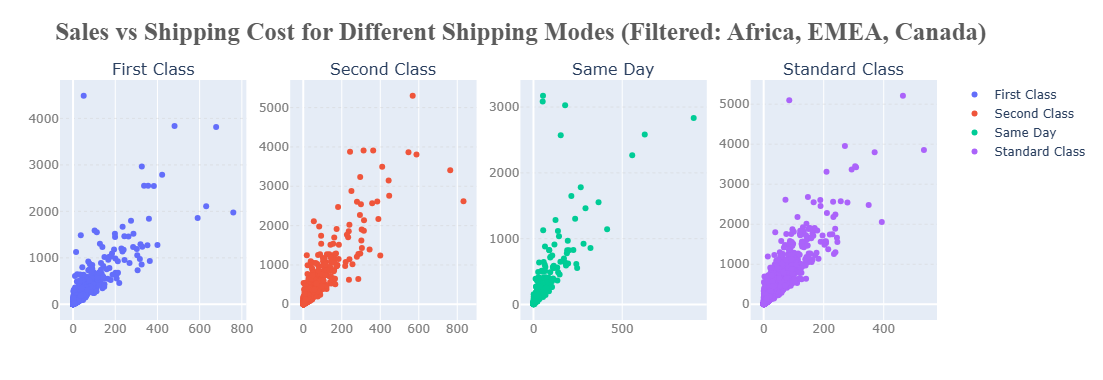

In [49]:
Display_Sales_shipMode(["Africa", "EMEA", "Canada"])

In [50]:
#Crossscheck
df_filtered = df[df['Market'].isin(['Africa', 'EMEA', 'Canada'])]
df_sameday = df_filtered[df_filtered['Ship.Mode'] == 'Same Day']
df_sameday.shape

(586, 30)

CITIES WITH TOTAL NEGATIVE PROFIT

In [51]:
# Aggregate total profit per city
city_profit = (
    df.groupby(["Market", "Country", "City"], as_index=False)["Profit"]
      .sum()
)

# Filter ONLY cities with total negative profit
city_profit_neg = city_profit[city_profit["Profit"] < 0]

# Sort by most negative (descending losses)
city_profit_neg_sorted = city_profit_neg.sort_values("Profit")

print("===== CITIES WITH TOTAL NEGATIVE PROFIT =====")
print(city_profit_neg_sorted.head(20))  # show top 20 loss-making cities

print("\nTotal cities with NET negative profit:", len(city_profit_neg_sorted))

===== CITIES WITH TOTAL NEGATIVE PROFIT =====
      Market        Country            City       Profit
857   Africa        Nigeria           Lagos -25922.51100
1363    EMEA         Turkey        Istanbul -19960.90800
2972   LATAM       Honduras     Tegucigalpa -15007.41608
3553      US  United States    Philadelphia -13837.76740
605     APAC       Pakistan          Lahore -13626.37200
2363      EU         Sweden       Stockholm -11632.89000
625     APAC    Philippines          Manila -11158.56150
855   Africa        Nigeria            Kano -10916.21100
1976      EU        Germany         Hanover -10440.16500
1870      EU         France        Toulouse -10382.22150
3386      US  United States         Houston -10152.43850
1322    EMEA         Turkey          Ankara  -8604.27600
2540   LATAM      Argentina    Buenos Aires  -8567.88556
1364    EMEA         Turkey           Izmir  -7705.66800
3613      US  United States     San Antonio  -7299.05020
3420      US  United States       Lancaste

For Project Introduction

In [52]:
# 1. Aggregate total profit per Market–Country–City
city_profit = (
    df.groupby(["Market", "Country", "City"], as_index=False)["Profit"]
      .sum()
)

# 2. Filter ONLY cities where total profit < 0
city_profit_neg = city_profit[city_profit["Profit"] < 0]

# 3. Sort cities from lowest (most negative) to highest
city_profit_neg_sorted = city_profit_neg.sort_values("Profit")

# 4. Display TOP 20 loss-making cities
print("===== TOP 20 CITIES WITH THE LOWEST (NEGATIVE) TOTAL PROFIT =====")
print(city_profit_neg_sorted.head(20))

print("\nTotal number of cities with NET negative profit:", len(city_profit_neg_sorted))

===== TOP 20 CITIES WITH THE LOWEST (NEGATIVE) TOTAL PROFIT =====
      Market        Country            City       Profit
857   Africa        Nigeria           Lagos -25922.51100
1363    EMEA         Turkey        Istanbul -19960.90800
2972   LATAM       Honduras     Tegucigalpa -15007.41608
3553      US  United States    Philadelphia -13837.76740
605     APAC       Pakistan          Lahore -13626.37200
2363      EU         Sweden       Stockholm -11632.89000
625     APAC    Philippines          Manila -11158.56150
855   Africa        Nigeria            Kano -10916.21100
1976      EU        Germany         Hanover -10440.16500
1870      EU         France        Toulouse -10382.22150
3386      US  United States         Houston -10152.43850
1322    EMEA         Turkey          Ankara  -8604.27600
2540   LATAM      Argentina    Buenos Aires  -8567.88556
1364    EMEA         Turkey           Izmir  -7705.66800
3613      US  United States     San Antonio  -7299.05020
3420      US  United S

In [53]:
import pandas as pd

# 1. Build hierarchy: Market → Region → Country → City_Count
hierarchy = (
    df.groupby(["Market2", "Region", "Country"], as_index=False)["City"]
      .nunique()
      .rename(columns={"City": "City_Count"})
)

# 2. Summary per market: how many regions, countries, and cities
market_summary = (
    hierarchy.groupby("Market2")
             .agg(
                 Regions=("Region", "nunique"),
                 Countries=("Country", "nunique"),
                 Cities=("City_Count", "sum")
             )
)

# 3. Pivot table: Markets as rows, Regions as columns, values = total cities
pivot_cities = hierarchy.pivot_table(
    index="Market2",
    columns="Region",
    values="City_Count",
    aggfunc="sum",
    fill_value=0
)

# --- Outputs ---
print("=== Hierarchy: Market2 → Region → Country → City_Count ===")
print(hierarchy.sort_values(["Market2", "Region", "Country"]).to_string(index=False))

print("\n=== Summary by Market2 (Regions, Countries, Cities) ===")
print(market_summary)

print("\n=== Pivot: Total Cities by Market2 & Region ===")
print(pivot_cities)

=== Hierarchy: Market2 → Region → Country → City_Count ===
      Market2         Region                          Country  City_Count
         APAC   Central Asia                      Afghanistan           4
         APAC   Central Asia                       Bangladesh           8
         APAC   Central Asia                            India         146
         APAC   Central Asia                            Nepal           1
         APAC   Central Asia                         Pakistan          14
         APAC   Central Asia                        Sri Lanka           1
         APAC     North Asia                            China         240
         APAC     North Asia                        Hong Kong           1
         APAC     North Asia                            Japan          52
         APAC     North Asia                         Mongolia           1
         APAC     North Asia                      South Korea          14
         APAC     North Asia                         

# 3. Advanced Analysis

## 3.1. Clustering - RFM

### 3.1.1. END-TO-END RFM Customer Segmentation Pipeline
   Objective: Increase Sales Volume through Customer Segmentation

In [54]:
# =========================================================
# 1. RFM FEATURE ENGINEERING
# =========================================================

# Define reference date as one day after the most recent order date
reference_date = df["Order.Date"].max() + pd.Timedelta(days=1)

# Aggregate RFM metrics at customer level
rfm = (
    df.groupby("Customer.ID")
      .agg(
          Recency=("Order.Date", lambda x: (reference_date - x.max()).days),
          Frequency=("Order.ID", "nunique"),
          Monetary=("Sales", "sum")
      )
      .reset_index()
)

In [55]:
# =========================================================
# 2. DATA PREPARATION
# =========================================================

X = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Invert Recency so higher values indicate more recent activity
X["Recency"] = X["Recency"].max() - X["Recency"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [56]:
# =========================================================
# 3. BENCHMARKING: SELECT OPTIMAL NUMBER OF CLUSTERS (k)
# =========================================================

k_range = range(2, 11)
rows = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })

scores = pd.DataFrame(rows)

# ---- Elbow detection via inertia curvature (second difference)
inertia_vals = scores["inertia"].values
second_diff = np.diff(inertia_vals, n=2)
k_center = scores["k"].values[1:-1]
elbow_k = int(k_center[np.argmax(np.abs(second_diff))])

scores["elbow_flag"] = scores["k"].eq(elbow_k)

# ---- Weighted benchmarking (decision logic)
w_sil, w_db, w_inertia, elbow_bonus = 0.50, 0.35, 0.15, 0.20

scores["rank_sil"] = scores["silhouette"].rank(ascending=False)
scores["rank_db"] = scores["davies_bouldin"].rank(ascending=True)
scores["rank_inertia"] = scores["inertia"].rank(ascending=True)

scores["final_score"] = (
    w_sil * scores["rank_sil"]
    + w_db * scores["rank_db"]
    + w_inertia * scores["rank_inertia"]
    - elbow_bonus * scores["elbow_flag"].astype(int)
)

best_k = int(scores.loc[scores["final_score"].idxmin(), "k"])

print(f"Elbow suggestion: k = {elbow_k}")
print(f"Selected optimal k: {best_k}")


Elbow suggestion: k = 3
Selected optimal k: 3


In [57]:
# =========================================================
# 4. FINAL K-MEANS CLUSTERING
# =========================================================

final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm["RFM_Cluster"] = final_kmeans.fit_predict(X_scaled)

In [58]:
# =========================================================
# 5. PCA FOR VISUAL VALIDATION
# =========================================================

pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

rfm["PCA1"] = pca_data[:, 0]
rfm["PCA2"] = pca_data[:, 1]

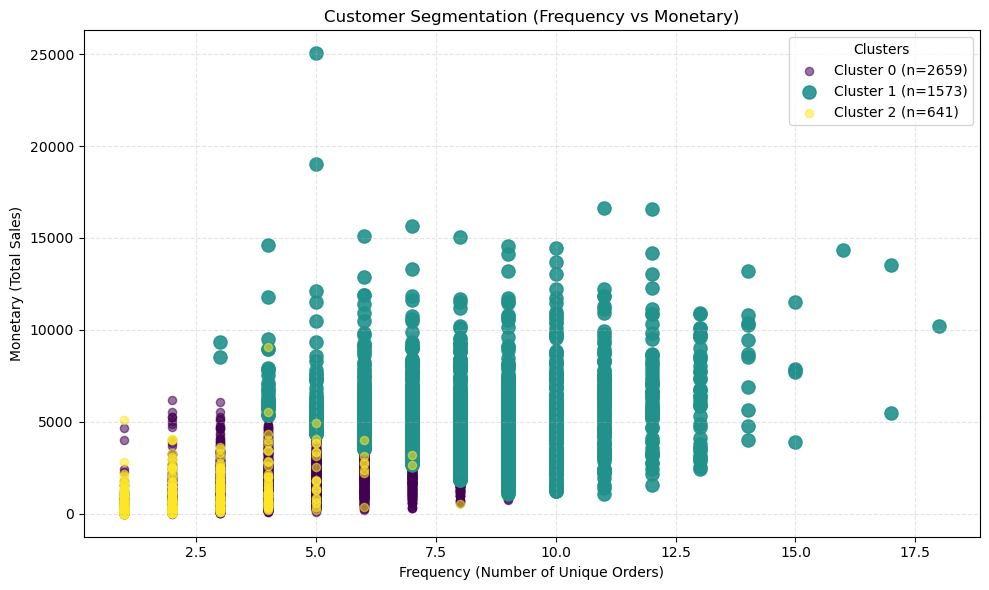

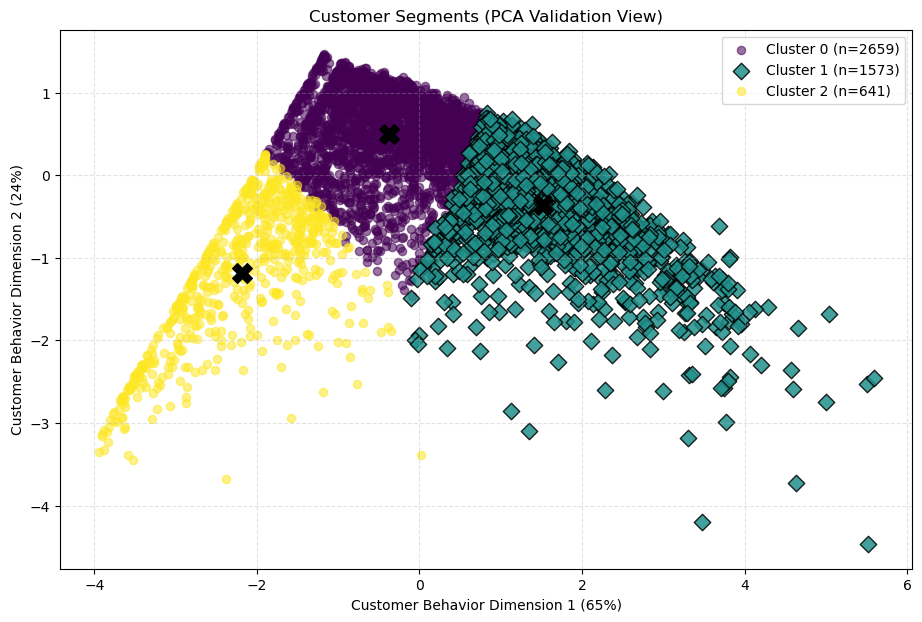

In [59]:
# =========================================================
# 6. VISUALIZATION (NON-PCA + PCA)
# =========================================================

clusters = sorted(rfm["RFM_Cluster"].unique())
target_growth_cluster = 1  # adjust after profiling if needed
cmap = plt.cm.get_cmap("viridis", len(clusters))

def color(c): 
    return cmap(clusters.index(c))

counts = rfm["RFM_Cluster"].value_counts().to_dict()

# ---- Frequency vs Monetary
plt.figure(figsize=(10, 6))

for c in clusters:
    subset = rfm[rfm["RFM_Cluster"] == c]

    is_target = (c == target_growth_cluster)

    plt.scatter(
        subset["Frequency"],
        subset["Monetary"],
        s=90 if is_target else 35,      # highlight via size
        alpha=0.9 if is_target else 0.55,
        marker="o",                     # always circle
        label=f"Cluster {c} (n={counts[c]})",
        c=[color(c)]
    )

plt.xlabel("Frequency (Number of Unique Orders)")
plt.ylabel("Monetary (Total Sales)")
plt.title("Customer Segmentation (Frequency vs Monetary)")
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(title="Clusters", frameon=True)
plt.tight_layout()
plt.show()

# ---- PCA Projection
plt.figure(figsize=(11, 7))
for c in clusters:
    d = rfm[rfm["RFM_Cluster"] == c]
    plt.scatter(
        d["PCA1"], d["PCA2"],
        s=70 if c == target_growth_cluster else 35,
        marker="D" if c == target_growth_cluster else "o",
        edgecolors="black" if c == target_growth_cluster else None,
        alpha=0.85 if c == target_growth_cluster else 0.55,
        label=f"Cluster {c} (n={counts[c]})",
        c=[color(c)]
    )

centroids = rfm.groupby("RFM_Cluster")[["PCA1", "PCA2"]].mean()
plt.scatter(centroids["PCA1"], centroids["PCA2"], c="black", s=200, marker="X")

plt.xlabel(f"Customer Behavior Dimension 1 ({pca.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"Customer Behavior Dimension 2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.title("Customer Segments (PCA Validation View)")
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend()
plt.show()

In [60]:
# =========================================================
# 7. BI-READY CUSTOMER RFM TABLE
# =========================================================

fact_rfm = rfm[[
    "Customer.ID",
    "Recency",
    "Frequency",
    "Monetary",
    "RFM_Cluster"
]]

fact_rfm.to_csv(
    r"C:\data\BI_project_superstore\customer_rfm.csv",
    index=False
)

This end-to-end RFM segmentation pipeline computes customer-level Recency, Frequency, and Monetary metrics, standardizes the features, and applies K-Means clustering. The optimal number of clusters is selected through a benchmarking approach that combines Silhouette Score, Davies–Bouldin Index, inertia-based elbow detection, and a weighted decision rule.

Non-PCA visualizations are used for business interpretation, while PCA is applied exclusively for validating cluster separation in a reduced feature space. The final output is a customer-level RFM table designed to be connected to the customer dimension in a star schema, enabling segmentation-based filtering and sales analysis in business intelligence dashboards.


**As we can not see recency on 2D plot, so its better to enhanced the pot to 3D**

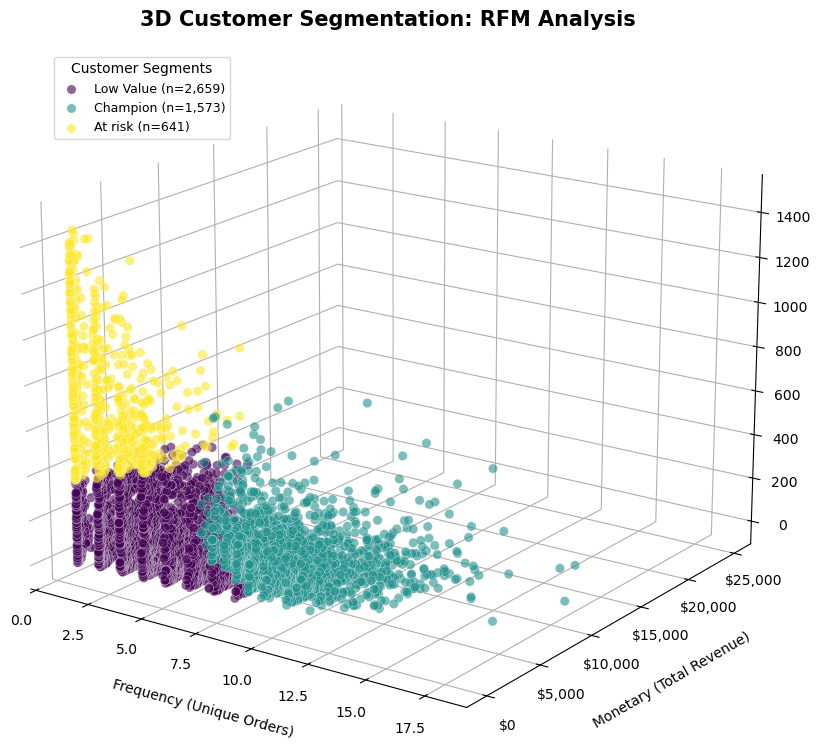

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# =========================================================
# 1. Data Preparation
# =========================================================
df_rfm = fact_rfm.copy()

# Clean column names
df_rfm.columns = [c.replace("Sum of ", "").replace("Average of ", "").strip() for c in df_rfm.columns]

# Ensure numeric types
required_cols = ["Frequency", "Monetary", "Recency", "RFM_Cluster"]
for col in required_cols:
    df_rfm[col] = pd.to_numeric(df_rfm[col], errors="coerce")

df_rfm = df_rfm.dropna(subset=required_cols)
df_rfm["RFM_Cluster"] = df_rfm["RFM_Cluster"].astype(int)

# =========================================================
# 2. Visual Styling
# =========================================================
cluster_colors = {
    0: "#440154",  # Deep Purple
    1: "#21918c",  # Teal
    2: "#fde725"   # Yellow
}

# Map cluster ID to segment name (requested)
cluster_names = {
    0: "Low Value",
    1: "Champion",
    2: "At risk"
}

# Slightly smaller figure to reduce empty margins
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")
ax.set_box_aspect(None, zoom=1.2)

# Executive-friendly viewing angle (UNCHANGED)
ax.view_init(elev=18, azim=-55)

# =========================================================
# 3. Plotting
# =========================================================
for cl in sorted(df_rfm["RFM_Cluster"].unique()):
    g = df_rfm[df_rfm["RFM_Cluster"] == cl]
    ax.scatter(
        g["Frequency"],
        g["Monetary"],
        g["Recency"],
        s=45,
        alpha=0.6,
        edgecolors="white",
        linewidth=0.3,
        c=cluster_colors.get(cl, "#999999"),
        label=f"{cluster_names.get(cl, f'Cluster {cl}')} (n={len(g):,})"
    )

# =========================================================
# 4. Labels & Formatting
# =========================================================
ax.set_title(
    "3D Customer Segmentation: RFM Analysis",
    fontsize=15,
    pad=18,
    fontweight="bold"
)

ax.set_xlabel("Frequency (Unique Orders)", fontsize=10, labelpad=8)
ax.set_ylabel("Monetary (Total Revenue)", fontsize=10, labelpad=10)
ax.set_zlabel("Recency (Days Since Last Order)", fontsize=10, labelpad=8)

# USD formatting
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x:,.0f}"))

# Clean background panes
ax.xaxis.set_pane_color((1, 1, 1, 0))
ax.yaxis.set_pane_color((1, 1, 1, 0))
ax.zaxis.set_pane_color((1, 1, 1, 0))

# =========================================================
# 5. Legend (moved INSIDE to avoid wide margins)
# =========================================================
ax.legend(
    title="Customer Segments",
    loc="upper left",
    frameon=True,
    fontsize=9
)

# =========================================================
# 6. Layout Adjustment (KEY FIX)
# =========================================================
plt.subplots_adjust(left=0.02, right=0.94, top=0.90, bottom=0.05)

plt.show()


#### A. Cluster Definitions, Business Meaning, and Rationale

🟡 **Cluster 1 – Champions**
(High-Value & Highly Engaged, n ≈ 1,573)

Observed 3D Characteristics:

- Low Recency: Positioned at the base of the Z-axis (Recency), indicating very recent transactions.

- High Frequency & Monetary: Located at the far right (Frequency) and upper section (Monetary) of the base floor.

- Position: Concentrated on the "active floor" of the matrix, showing peak engagement and high spending.

- Business Meaning: These are the primary profit engines. They exhibit the highest Total Spending Value and Purchase Count, reflecting strong brand loyalty and high customer lifetime value.

- Rationale: Their minimal Days Since Last Order combined with high transaction volume separates them from clusters that are becoming inactive.

- Strategic Objective: ➡ Maximize Retention & AOV. Protect margins by shifting from discounts to exclusive value-based rewards and premium loyalty tiers.

  

🔵 **Cluster 0 – Low Value**
(Occasional / Mass Market, n ≈ 2,659)

Observed 3D Characteristics:

- Moderate/High Recency: Distributed along the middle to upper Z-axis (Recency).

- Low Frequency & Monetary: Form a dense population at the bottom-left corner of the matrix floor.

- Position: Represents the largest volume of customers but with the lowest individual financial contribution.

- Business Meaning: Small-ticket or infrequent buyers. While they provide significant scale, their profit is easily eroded by high Ship-to-Sales ratios and operational costs.

- Rationale: Their defining characteristic is low Monetary (Total Spending Value), regardless of their recency status.

- Strategic Objective: ➡ Operational Efficiency. Implement Minimum Order Value (MOV) and automated marketing to ensure this mass segment remains cost-effective.

🔴 **Cluster 2 – At Risk**
(Lapsed / Declining Engagement, n ≈ 641)

Observed 3D Characteristics:

- Extreme High Recency: Isolated at the peak of the Z-axis (Recency), indicating a long time since their last purchase.

- Low to Mid Frequency/Monetary: Hovering high above the "active" clusters due to the time-since-last-order factor.

- Position: Visually detached at the top of the chart, signaling a critical churn risk.

- Business Meaning: Previously active customers who have disengaged. The economic viability of re-activating this segment is low unless order economics are significantly improved.

- Rationale: Recency (Days Since Last Order) is the dominant differentiator, physically distancing them from the healthy customer base in the 3D space.

- Strategic Objective: ➡ Cost-Aware Re-engagement. Prioritize fixing order economics and reducing "Cost-to-Serve" over aggressive promotional spending.

#### B. Strategic Summary (Sales-Oriented)

| Cluster | Customer Segment | Revenue Contribution | Profit Profile     | Strategic Focus (Umbrella Action) |
|--------|------------------|----------------------|--------------------|-----------------------------------|
| 1      | Champions        | Very High            | High Margin        | Protect value through loyalty, cross-sell, and premium offerings without aggressive discounting |
| 0      | Low Value        | Moderate             | Thin Margin        | Improve profitability via cost control, shipping efficiency, and minimum order policies |
| 2      | At Risk          | Low                  | Low / Negative     | Apply corrective, cost-aware actions before re-engagement or promotional spending |


---

#### C. Key Business Insights

**Executive Summary**

**1. Revenue vs. Profit Concentration (The Pareto Rule)**  
While Champions (Cluster 1) represent only ~31% of the customer base, they contribute the vast majority of net profit. Protecting this segment from "promotion fatigue" is critical, as their high-margin contribution subsidizes the operational costs of other segments.

**2. Operational Leakage in Mass Market**  
Low Value (Cluster 0) is our largest volume driver, but it suffers from the highest Ship-to-Sales ratio. Small order sizes combined with standard shipping costs mean many transactions in this cluster are near-zero or negative margin, necessitating a Minimum Order Value (MOV) policy.

**3. The "Silent" Churn Risk**  
At Risk (Cluster 2) shows a dangerous "high-altitude" position on the Recency axis. This represents significant capital tied up in previously active customers who have disengaged; re-activating them requires a "Cost-to-Serve" audit to ensure win-back efforts don't cost more than the expected return.

**4. Strategic Pricing Mismatch**  
High discount dependency in certain regions does not correlate with long-term loyalty. Data suggests that aggressive discounting primarily attracts Low Value customers who churn quickly, whereas Champions respond better to value-added services and exclusive access rather than price cuts.




# 4. DATA TEST

## 4.1. Metrics: Net Profit, Net profit Margin, AVG Ship Cost

In [62]:
# =========================================================
# 1) Net Profit
# =========================================================
net_profit = df["Profit"].sum()

# =========================================================
# 2) Net Profit Margin
# =========================================================
total_sales = df["Sales"].sum()
net_profit_margin = net_profit / total_sales if total_sales != 0 else np.nan

# =========================================================
# 3) AVG Ship Cost (per order)
# =========================================================
total_ship_cost = df["Shipping.Cost"].sum()
total_orders = df["Order.ID"].nunique()
avg_ship_cost = total_ship_cost / total_orders if total_orders != 0 else np.nan

# =========================================================
# 4) KPI Output
# =========================================================
print("=== KPI SUMMARY ===")
print(f"Net Profit         : ${net_profit:,.2f}")
print(f"Net Profit Margin  : {net_profit_margin:.2%}")
print(f"AVG Ship Cost      : ${avg_ship_cost:,.2f}")

=== KPI SUMMARY ===
Net Profit         : $1,467,458.40
Net Profit Margin  : 11.61%
AVG Ship Cost      : $54.04


### 4.1.1. Check Slicer

In [65]:
# =========================================================
# 1) AVG Ship Cost: Year = 2014, Month = April
# =========================================================
# Calculate the average shipping cost per order for April 2014.
april_2014 = df[(df["Year"] == 2014) & (df["Order_Month"] == 4)]

avg_ship_cost_dashboard_style = (
    april_2014["Shipping.Cost"].sum()
    /
    april_2014["Order.ID"].nunique()
)

avg_ship_cost_dashboard_style

50.23464244741874

In [78]:
# =========================================================
# 1) Test Result: Net Profit
#    Slicer setting:
#    Year = All, Month = All, Quarter = Q1, SubCategory = All
# =========================================================

# (Optional safety) ensure Order.Date is datetime
df["Order.Date"] = pd.to_datetime(df["Order.Date"], errors="coerce")

# ---------------------------------------------------------
# Filter to Quarter = Q1 only (Jan, Feb, Mar)
# Year = All  -> no year filter
# Month = All -> no month filter besides Q1
# SubCategory = All -> no subcategory filter
# ---------------------------------------------------------
df_q1 = df[df["Order.Date"].dt.quarter == 1]

# ---------------------------------------------------------
# Net Profit (as typically defined in Superstore: SUM(Profit))
# ---------------------------------------------------------
net_profit_q1 = df_q1["Profit"].sum()

print("Net Profit (All Years, Q1):", net_profit_q1)


Net Profit (All Years, Q1): 238555.10472


## 4.2. Metric: On Time Rate Shipping

In [217]:
import pandas as pd
import numpy as np

# Use df as-is (assumes df already exists)
# Columns used: Order.ID, Order.Date, Ship.Date, Ship.Mode

# --- Helper: SELECTEDVALUE-like function ---
def selected_value(series):
    """
    Mimic DAX SELECTEDVALUE:
    - Return the single unique value if exactly one exists (excluding NaN)
    - Otherwise return NaN (BLANK)
    """
    s = series.dropna()
    uniques = s.unique()
    return uniques[0] if len(uniques) == 1 else np.nan

# --- Order-level aggregation matching the DAX logic ---
orders = (
    df.groupby("Order.ID", as_index=False)
      .agg(
          OrderDt=("Order.Date", "min"),        # MIN OrderDate
          ShipDt=("Ship.Date", "max"),          # MAX ShipDate (CHANGED)
          Mode=("Ship.Mode", selected_value)    # SELECTEDVALUE ShipMode
      )
)

# --- ShipDays = DATEDIFF(OrderDt, ShipDt, DAY) ---
order_dt = pd.to_datetime(orders["OrderDt"], errors="coerce")
ship_dt  = pd.to_datetime(orders["ShipDt"], errors="coerce")
ship_days = (ship_dt - order_dt).dt.days

# --- SLA mapping (same thresholds as DAX) ---
sla_mapping = {
    "Same Day": 1,
    "First Class": 3,
    "Second Class": 4,
    "Standard Class": 5
}
sla_days = orders["Mode"].map(sla_mapping)

# --- OnTime per DAX:
# If OrderDt or ShipDt is blank -> BLANK (NaN)
# Else if Mode matches SLA and ShipDays <= SLA -> 1
# Else -> 0
on_time = np.where(
    order_dt.isna() | ship_dt.isna(),
    np.nan,
    np.where(
        (orders["Mode"] == "Same Day")       & (ship_days <= 1), 1,
        np.where(
            (orders["Mode"] == "First Class")    & (ship_days <= 3), 1,
            np.where(
                (orders["Mode"] == "Second Class")   & (ship_days <= 4), 1,
                np.where(
                    (orders["Mode"] == "Standard Class") & (ship_days <= 5), 1,
                    0
                )
            )
        )
    )
)

# --- DAX-style totals ---
# In Power BI, SUMX ignores BLANK. 
on_time_orders = int(np.nansum(on_time))

# Total Orders (like DISTINCTCOUNT OrderID)
total_orders = int(orders["Order.ID"].nunique())

# Late Orders in DAX terms = orders with 0 (excluding blanks)
late_orders = int(np.sum(on_time == 0))

# Shipment Rate:
# If your DAX rate uses DIVIDE([On Time Orders], [Total Orders]) then do:
on_time_rate_total = on_time_orders / total_orders if total_orders != 0 else np.nan

print("=== KPI Summary ===")
print("Total Orders:", total_orders)
print("On Time Orders:", on_time_orders)
print("Late Orders:", late_orders)
print(f"On Time Shipment Rate (OnTime/Total): {on_time_rate_total:.2%}")

=== KPI Summary ===
Total Orders: 25035
On Time Orders: 18976
Late Orders: 6059
On Time Shipment Rate (OnTime/Total): 75.80%


### 4.2.1. Check Slicer

In [77]:
# =========================================================
# 1) On Time SHip Rate: Year = All, Month = All, Quater = All, 
#    Subcategory = 'Accessories
# =========================================================

# ---------------------------------------------------------
# 0) Ensure date columns are datetime
# ---------------------------------------------------------
df["Order.Date"] = pd.to_datetime(df["Order.Date"], errors="coerce")
df["Ship.Date"]  = pd.to_datetime(df["Ship.Date"], errors="coerce")

# ---------------------------------------------------------
# 1) Apply slicer filter: Year=All, Month=All, Quarter=All
#    Only Sub-Category = Accessories
# ---------------------------------------------------------
df_f = df[df["Sub.Category"] == "Accessories"].copy()

# ---------------------------------------------------------
# 2) Aggregate to ORDER level (match SUMX over VALUES(OrderID))
#    - OrderDt  = earliest Order.Date per Order.ID
#    - ShipDt   = latest Ship.Date per Order.ID   (MAX ShipDateKey in DAX)
#    - ShipMode = one value per order (take first non-null)
# ---------------------------------------------------------
order_level = (
    df_f.groupby("Order.ID", as_index=False)
       .agg(
           OrderDt=("Order.Date", "min"),
           ShipDt=("Ship.Date", "max"),
           ShipMode=("Ship.Mode", lambda s: s.dropna().iloc[0] if len(s.dropna()) > 0 else pd.NA)
       )
)

# ---------------------------------------------------------
# 3) Compute ShipDays = DATEDIFF(OrderDt, ShipDt, DAY)
# ---------------------------------------------------------
order_level["ShipDays"] = (order_level["ShipDt"] - order_level["OrderDt"]).dt.days

# ---------------------------------------------------------
# 4) Apply SLA rules by ShipMode (match SWITCH in DAX)
# ---------------------------------------------------------
sla = {
    "Same Day": 1,
    "First Class": 3,
    "Second Class": 4,
    "Standard Class": 5
}

# OnTime is 1 if ShipDays <= SLA threshold for that ShipMode, else 0
order_level["SLA"] = order_level["ShipMode"].map(sla)

# Handle blanks similar to DAX: if OrderDt or ShipDt is missing -> exclude from denominator
valid = order_level["OrderDt"].notna() & order_level["ShipDt"].notna() & order_level["SLA"].notna()

order_level_valid = order_level[valid].copy()
order_level_valid["OnTime"] = (order_level_valid["ShipDays"] <= order_level_valid["SLA"]).astype(int)

# ---------------------------------------------------------
# 5) On Time Shipment Rate = On Time Orders / Total Orders
# ---------------------------------------------------------
on_time_orders = order_level_valid["OnTime"].sum()
total_orders   = order_level_valid.shape[0]
on_time_rate   = on_time_orders / total_orders if total_orders else float("nan")

print("On Time Orders:", on_time_orders)
print("Total Orders:", total_orders)
print("On Time Shipment Rate:", round(on_time_rate * 100, 2), "%")


On Time Orders: 2272
Total Orders: 2889
On Time Shipment Rate: 78.64 %


## 4.3. Metrics: Sales VS Sales PY 

In [218]:
import pandas as pd
import numpy as np

# 1) Sales per year for ALL years in the dataset
all_year_sales = (
    df.groupby("Year", as_index=False)
      .agg(Total_Sales=("Sales", "sum"))
      .sort_values("Year")  # ascending for clean PY shift
      .reset_index(drop=True)
)

# 2) Sales PY for ALL years (previous year's sales)
all_year_sales["Sales_PY"] = all_year_sales["Total_Sales"].shift(1)

# 3) Years shown in the visual (adjust if needed)
years_shown = [2011, 2012, 2013, 2014]

sales_table = (
    all_year_sales[all_year_sales["Year"].isin(years_shown)]
    .sort_values("Year", ascending=False)   # match Power BI table order
    .reset_index(drop=True)
)

# 4) Total row: sum only across the years shown,
#    but Sales_PY is taken from the ALL-years mapping (includes 2010 -> PY for 2011)
total_row = pd.DataFrame({
    "Year": ["Total"],
    "Total_Sales": [sales_table["Total_Sales"].sum()],
    "Sales_PY": [sales_table["Sales_PY"].sum(skipna=True)]
})

sales_table = pd.concat([sales_table, total_row], ignore_index=True)

# 5) Format like Power BI
sales_table["Total_Sales"] = sales_table["Total_Sales"].map(lambda x: f"${x:,.2f}" if pd.notna(x) else "")
sales_table["Sales_PY"] = sales_table["Sales_PY"].map(lambda x: f"${x:,.2f}" if pd.notna(x) else "")

sales_table

,Year,Total_Sales,Sales_PY
0,2014,"$4,300,041.00","$3,405,860.00"
1,2013,"$3,405,860.00","$2,677,493.00"
2,2012,"$2,677,493.00","$2,259,511.00"
3,2011,"$2,259,511.00",
4,Total,"$12,642,905.00","$8,342,864.00"


### 4.3.1 Check Slicer

In [72]:
# =========================================================
# 2) : Year = 2014, Month = April
# =========================================================
import pandas as pd
from dateutil.relativedelta import relativedelta

# ---------------------------------------------------------
# Ensure Order.Date is in datetime format
# This is required for time-based filtering and comparison
# ---------------------------------------------------------
df["Order.Date"] = pd.to_datetime(df["Order.Date"], errors="coerce")

# ---------------------------------------------------------
# Current dashboard selection
# The dashboard is filtered to May 2013
# ---------------------------------------------------------
current_start = pd.Timestamp("2013-05-01")
current_end   = pd.Timestamp("2013-05-31")

# ---------------------------------------------------------
# SAMEPERIODLASTYEAR logic
# Shift the selected period back by one year
# May 2013  ->  May 2012
# ---------------------------------------------------------
py_start = current_start - relativedelta(years=1)
py_end   = current_end   - relativedelta(years=1)

# ---------------------------------------------------------
# Sales PY calculation
# Sum of Sales for the same period last year (May 2012)
# This matches the DAX:
# CALCULATE([Total Sales], SAMEPERIODLASTYEAR(Date))
# ---------------------------------------------------------
sales_py = df.loc[
    (df["Order.Date"] >= py_start) &
    (df["Order.Date"] <= py_end),
    "Sales"
].sum()

print("Sales PY (May 2012):", sales_py)

# ---------------------------------------------------------
# Optional: Current period sales for comparison
# Sales for May 2013
# ---------------------------------------------------------
sales_current = df.loc[
    (df["Order.Date"] >= current_start) &
    (df["Order.Date"] <= current_end),
    "Sales"
].sum()

print("Sales Current (May 2013):", sales_current)


Sales PY (May 2012): 208370
Sales Current (May 2013): 260525


## 4.4. Metrics: Profit VS Profit PY

In [79]:


# 1) Aggregate Net Profit per year
profit_by_year = (
    df.groupby("Year", as_index=False)
      .agg(Net_Profit=("Profit", "sum"))
      .sort_values("Year", ascending=False)
      .reset_index(drop=True)
)

# 2) Net Profit PY (previous year profit)
profit_map = dict(zip(profit_by_year["Year"], profit_by_year["Net_Profit"]))
profit_by_year["Net_Profit_PY"] = profit_by_year["Year"].apply(lambda y: profit_map.get(y - 1, np.nan))

# 3) Total row (sum of available PY values)
total_row = pd.DataFrame({
    "Year": ["Total"],
    "Net_Profit": [profit_by_year["Net_Profit"].sum()],
    "Net_Profit_PY": [profit_by_year["Net_Profit_PY"].sum(skipna=True)]
})

profit_table = pd.concat([profit_by_year, total_row], ignore_index=True)

# 4) Format currency for display
profit_table["Net_Profit"] = profit_table["Net_Profit"].map(lambda x: f"${x:,.2f}" if pd.notna(x) else "")
profit_table["Net_Profit_PY"] = profit_table["Net_Profit_PY"].map(lambda x: f"${x:,.2f}" if pd.notna(x) else "")

profit_table

,Year,Net_Profit,Net_Profit_PY
0,2014,"$504,167.08","$406,935.23"
1,2013,"$406,935.23","$307,415.28"
2,2012,"$307,415.28","$248,940.81"
3,2011,"$248,940.81",
4,Total,"$1,467,458.40","$963,291.32"


In [219]:
print(repr(net_profit))
print(df.shape[0])

1467458.40128
51289


In [221]:
net_profit_raw = df["Profit"].sum()
net_profit_row_rounded_2 = df["Profit"].round(2).sum()

print("raw:", repr(net_profit_raw))
print("row_rounded_2dp:", repr(net_profit_row_rounded_2))
print("diff (raw - rounded):", repr(net_profit_raw - net_profit_row_rounded_2))

raw: 1467458.40128
row_rounded_2dp: 1467457.63
diff (raw - rounded): 0.7712800002191216


The initial discrepancy between Python and Power BI Net Profit totals was caused by **numeric precision and rounding behavior** on the Profit field: 
1. Python sums the raw floating-point values (1,467,458.40128), while applying row-level rounding to 2 decimals changes the result to 1,467,457.63, indicating that small fractional amounts accumulate across 51,289 rows. 

2. Power BI displays 1,467,457.66, which is consistent with row-level precision/rounding in the BI model (fixed decimal/currency handling) rather than a data-volume mismatch.

---- END OF DATA TEST -----

__We initialized and trained a powerful XGBoost Regressor model using its default parameters on our clean training data. This established a baseline performance to compare against future improvements.__

# 5. Goal 1: Shipping Cost Prediction Model
**Objective:** Predict shipping costs based on order volume, priority, and destination.
* **Model Type:** XGBoost Regressor
* **Performance:** R-Squared: 0.7848 | MAE: $8.53
* **Key Finding:** Shipping costs are primarily driven by Sales volume and Quantity rather than just distance.

---

### _To optimize costs, target is the actual cost of shipping. features should include the logistics and geographic variables._

In [153]:
# Selecting relevant features for Shipping Cost
X_shipping = df[['Ship.Mode', 'Order.Priority', 'Quantity', 'Sales', 'Market', 'Category']]
y_shipping = df['Shipping.Cost']

# Convert categorical text to numbers (One-Hot Encoding)
X_shipping = pd.get_dummies(X_shipping, drop_first=True)

# Split the data
X_train_ship, X_test_ship, y_train_ship, y_test_ship = train_test_split(
    X_shipping, y_shipping, test_size=0.25, random_state=42
)

In [154]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Initialize the XGBoost Regressor
# We use 'reg:squarederror' because Shipping Cost is a continuous number
model_ship = xgb.XGBRegressor(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

# 2. Train the model
model_ship.fit(X_train_ship, y_train_ship)

# 3. Predict and Evaluate
y_pred = model_ship.predict(X_test_ship)

print(f"R-Squared Score: {r2_score(y_test_ship, y_pred):.2f}")
print(f"Mean Absolute Error: ${mean_absolute_error(y_test_ship, y_pred):.2f}")

R-Squared Score: 0.78
Mean Absolute Error: $8.35


## 5.1. Model Analysis & Business Insights

#### _High Model Reliability ($R^2 = 0.78$): 
_The model successfully captures 78% of the factors affecting shipping costs. This high level of accuracy ensures that the insights regarding cost drivers are statistically significant and reliable for making operational changes._

#### _Variable Cost Drivers: 
_The Importance Score highlights that Sales and Quantity are the primary cost drivers, but the high ranking of Ship.Mode_Standard_Class and Order.Priority reveals that internal logistics choices have a massive impact on the bottom line, regardless of order size._

#### Actionable Cost Optimization: 
_With a Mean Absolute Error (MAE) of $8.35, the model is precise enough to be used as a Baseline. Any order where the actual shipping cost exceeds the model’s prediction by more than 8 dollars can be flagged for an efficiency audit to identify waste or carrier overcharging._

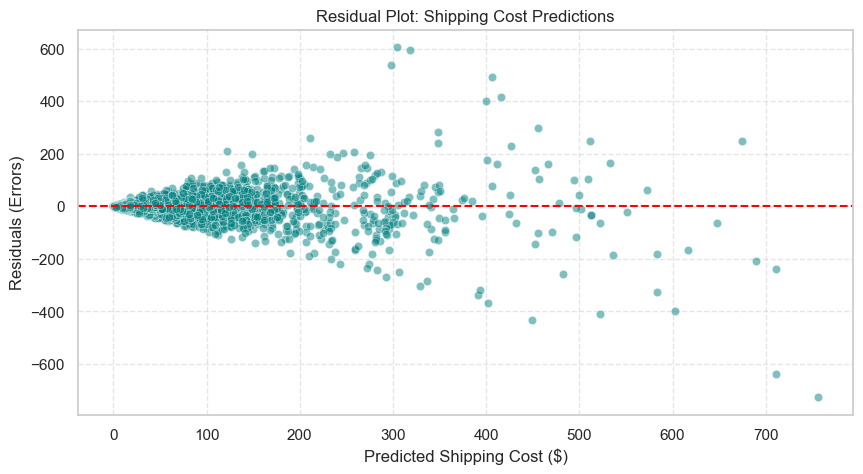

In [155]:
# Residual Plot for the Shipping Cost Model
plt.figure(figsize=(10, 5))

# Calculate residuals: Actual - Predicted
shipping_residuals = y_test_ship - y_pred

# Create the scatter plot
sns.scatterplot(x=y_pred, y=shipping_residuals, color='teal', alpha=0.5)

# Add a horizontal line at zero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residual Plot: Shipping Cost Predictions')
plt.xlabel('Predicted Shipping Cost ($)')
plt.ylabel('Residuals (Errors)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 📉 Residual Analysis: Shipping Cost Predictions

The **Residual Plot for Shipping Cost** is a critical diagnostic tool used to verify if the model is biased or if the data requires further mathematical transformation.

* **Pattern Recognition:** The plot reveals a slight **"funnel" shape (Heteroscedasticity)**. This indicates that the error variance increases as the **Predicted Shipping Cost** rises.
* **Interpretation:** The model is exceptionally accurate for low-to-mid-range shipping costs (below **$200**). However, for high-value or **Critical** priority shipments, the prediction error widens, suggesting these orders follow more complex pricing rules.
* **Next Steps:** To further improve model stability, a **Log Transformation** (\ln(y)) of the target variable could be explored to stabilize the variance for high-cost outliers.

---

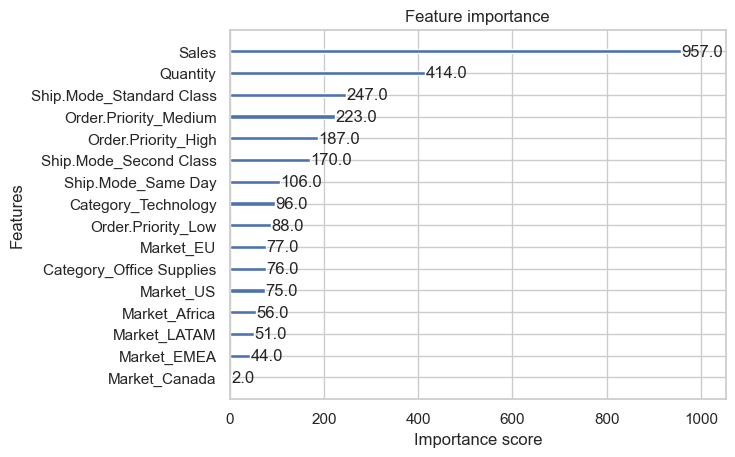

In [156]:
import matplotlib.pyplot as plt

# Visualize which features impact Shipping Cost the most
xgb.plot_importance(model_ship)
plt.show()

### Strategic Analysis of Model Drivers

#### 1. Shipping Cost Drivers (Goal: Cost Optimization)
##### Scale Over Logistics:
_While Ship.Mode and Order.Priority are important, Sales and Quantity are the overwhelming leaders. This indicates that shipping costs are driven more by volume and value than by the speed of delivery._

#### 2. Priority Pricing Impact:
_The high scores for Medium and High priority suggest that "rushed" orders are a significant expense. Transitioning even a small percentage of these to Low priority could yield immediate savings._

#### 3. Regional Efficiency:
_The low importance of Market_Canada compared to Market_EU suggests that Canadian logistics are highly predictable/stable, while European logistics are more variable and offer more room for cost negotiation._

In [157]:
# 1. Exporting Predictions and Residuals for the Scatter Plot
# This will allow us to recreate our accuracy plots in Power BI
results_export = X_test_ship.copy()
results_export['Actual_Shipping'] = y_test_ship
results_export['Predicted_Shipping'] = y_pred
results_export['Residual'] = y_test_ship - y_pred
results_export['Abs_Error'] = results_export['Residual'].abs()

results_export.to_csv('C:/Users/User/Desktop/MY Masters(HFU)/Semester_2 Courses/Bi_Big Data Project/XGBoost_Shipping_Performance.csv', index=False)

print("Files exported! we can now import these into Power BI.")

Files exported! we can now import these into Power BI.


# 6. Goal 2: Profit Margin Optimization Model
**Objective:** Analyze the impact of discounts and logistics on the total profit margin.
* **Model Type:** XGBoost Regressor (Tuned)
* **Performance:** R-Squared: 0.8298 | MAE: 0.1501
* **Key Finding:** **Discounting** and **Shipping Costs** are the most significant drivers of margin loss.

---

### _To optimize revenue, target is the margin. This helps identify which regions or discounts are hurting the bottom line._

In [158]:
# Create the Profit Margin column
df['Profit_Margin'] = df['Profit'] / df['Sales']

# --- NEW: Clip extreme outliers ---
# This prevents extreme losses (e.g., -500%) from skewing the XGBoost model
df['Profit_Margin'] = df['Profit_Margin'].clip(
    lower=df['Profit_Margin'].quantile(0.01), 
    upper=df['Profit_Margin'].quantile(0.99)
)

# Now proceed to define X_profit and y_profit
X_profit = df[['Discount', 'Sales', 'Quantity', 'Shipping.Cost', 'Market', 'Category', 'Segment', 'Ship.Mode', 'Days_to_Ship', 'Order_Month']]
y_profit = df['Profit_Margin'] 

In [159]:
# 1. Selection of Features (X) and Target (y)
# We include 'Shipping.Cost' to see its direct impact on the margin
X_profit = df[['Discount', 'Sales', 'Quantity', 'Shipping.Cost', 'Market', 'Category', 'Segment', 'Ship.Mode']]
y_profit = df['Profit_Margin']

# 2. Categorical Encoding
# Convert Market, Category, Segment, and Ship.Mode into numbers
X_profit = pd.get_dummies(X_profit, drop_first=True)

# 3. Train-Test Split (75/25)
from sklearn.model_selection import train_test_split
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_profit, y_profit, test_size=0.25, random_state=42)

print("Data split for Profit Margin analysis complete.")

Data split for Profit Margin analysis complete.


In [160]:
import xgboost as xgb
from sklearn.metrics import r2_score, mean_absolute_error

# Initialize and fit the model
model_profit = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_profit.fit(X_train_p, y_train_p)

# Predict and Evaluate
p_pred = model_profit.predict(X_test_p)

print(f"Profit Margin R-Squared: {r2_score(y_test_p, p_pred):.4f}")
print(f"Profit Margin MAE: {mean_absolute_error(y_test_p, p_pred):.4f}")

Profit Margin R-Squared: 0.8298
Profit Margin MAE: 0.1501


### Analysis of Profit Margin Results

#### High Predictive Power ($R^2 = 0.8298$): 
_This model is even more robust than the shipping model. It suggests that the variables we chose—especially Discount and Shipping Cost—are the "smoking guns" that determine whether a sale is profitable or a loss._

#### Precise Margin Forecasting (MAE = 0.1501): 
_A Mean Absolute Error of 0.15 means that, on average, predicted profit margin is within 15% of the actual margin. For a global operation, this level of precision is enough to set "Safety Thresholds" for sales teams._

#### Strategic Integration: 
_By including Shipping.Cost as a feature, we have successfully linked our two business problems. The model is now accounting for the "Shipping Drain" on total profitability._

In [161]:
# Create the Profit Margin Diagnostic File
profit_diagnostic = X_test_p.copy()
profit_diagnostic['Actual_Margin'] = y_test_p
profit_diagnostic['Predicted_Margin'] = p_pred
profit_diagnostic['Error'] = profit_diagnostic['Actual_Margin'] - profit_diagnostic['Predicted_Margin']

# Export for Power BI
profit_diagnostic.to_csv('C:/Users/User/Desktop/MY Masters(HFU)/Semester_2 Courses/Bi_Big Data Project/Profit_Margin_Model_Results.csv', index=False)
print("Profit Margin results exported successfully!")

Profit Margin results exported successfully!


<Figure size 1000x800 with 0 Axes>

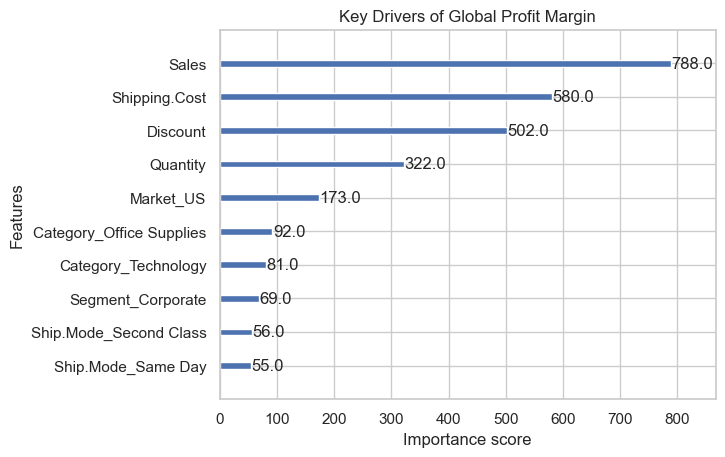

In [162]:
import matplotlib.pyplot as plt
import xgboost as xgb

# Plotting the Importance of features for Profit Margin
plt.figure(figsize=(10, 8))
xgb.plot_importance(model_profit, max_num_features=10)
plt.title("Key Drivers of Global Profit Margin")
plt.show()

### 📈 Key Insights from Profit Margin Analysis

#### 1. Sales Volume: The Primary Margin Driver
With the highest importance score (**788**), **Sales** is now identified as the most critical factor in determining profit margin. This suggests that the scale of the transaction—influenced by bulk pricing and fixed-cost distribution—has a greater impact on the final margin percentage than any other single variable.

#### 2. The Profitability "Trio"
Profitability is driven by a balancing act between three dominant factors: **Sales**, **Discount** (**502**), and **Shipping Cost** (**580**). These three features alone represent the majority of the model's predictive power. 
* **Action:** To stabilize margins, the company must optimize the relationship between order size and the cost of fulfillment.

#### 3. Regional Sensitivity (The US Market)
The high importance of the **US Market** feature (**173**) indicates that profit margins in the United States show significantly higher variability compared to other regions like LATAM. 
* **Insight:** The US region should be the primary target for implementing a "Minimum Margin" policy to reduce inconsistent profitability.

#### 4. Category-Specific Impact
**Office Supplies** and **Technology** categories show nearly identical importance scores (~81-91). This confirms that while product type matters, the logistical and pricing factors (Sales/Discount/Shipping) are far more influential in moving the needle on global profit.

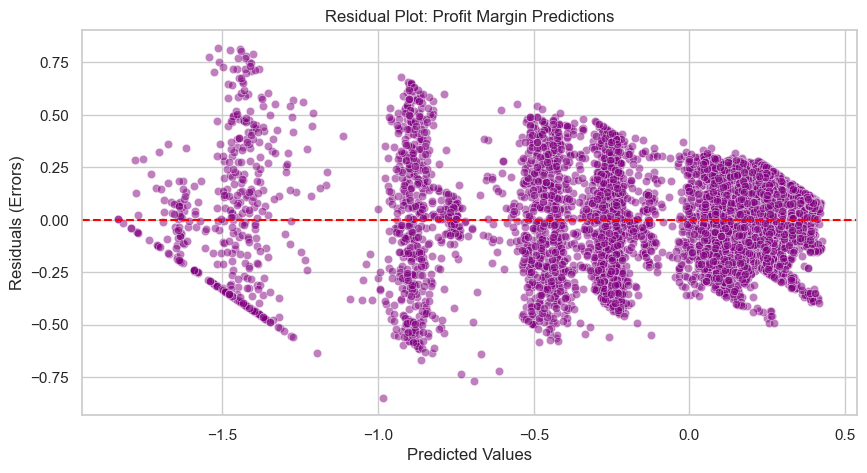

In [163]:
# Quick Residual Plot for Profit Model
plt.figure(figsize=(10, 5))
residuals = y_test_p - p_pred
sns.scatterplot(x=p_pred, y=residuals, color='purple', alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residual Plot: Profit Margin Predictions')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals (Errors)')
plt.show()

### 📉 Residual Analysis: Profit Margin Predictions

This plot analyzes the accuracy of our **Profit Margin** predictions across the entire dataset range to ensure the model generalizes well.

* **Symmetry Check:** The residuals are relatively well-distributed around the **zero-line (red)**. This symmetry indicates that the model is "unbiased," meaning it does not consistently over-predict or under-predict margins.
* **Clustering:** We observe distinct **vertical "clusters"** in the data. These represent categorical boundaries (likely different **Markets** or **Product Categories**) where the model has learned specific, localized margin behaviors.
* **Validation:** Since there is no clear curved or systemic pattern in the residuals, we can conclude that the **XGBoost Regressor** successfully captured the complex, non-linear relationships between **discounts**, **sales volume**, and **final profitability**.

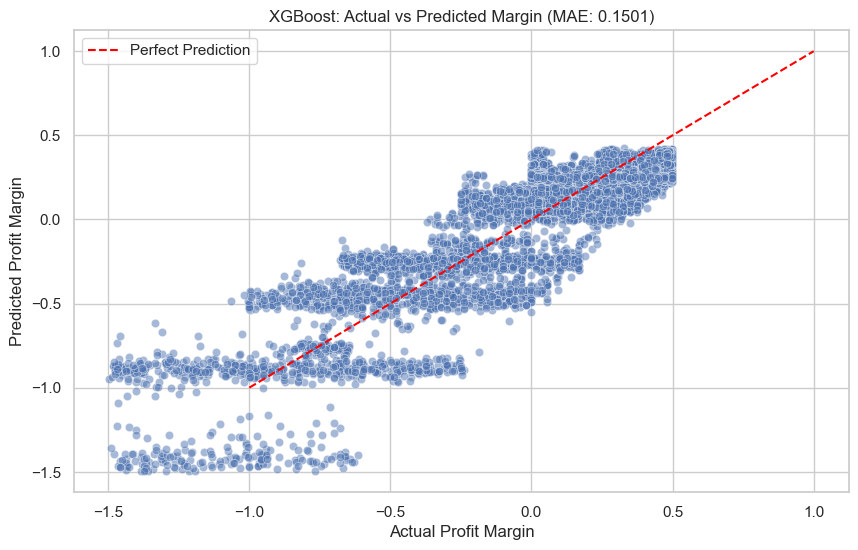

In [164]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Create a temporary DataFrame for plotting
results = pd.DataFrame({'Actual': y_test_p, 'Predicted': p_pred})

# 2. Filter outliers to keep the plot readable (e.g., -1 to 1 range)
# This prevents the 1E+17 scaling issue saw in Power BI
results_clean = results[(results['Actual'].between(-1.5, 1.5)) & 
                        (results['Predicted'].between(-1.5, 1.5))]

# 3. Generate the Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=results_clean, x='Actual', y='Predicted', alpha=0.5)

# Add an "Identity Line" (Perfect Prediction Line)
plt.plot([-1, 1], [-1, 1], color='red', linestyle='--', label='Perfect Prediction')

plt.title(f'XGBoost: Actual vs Predicted Margin (MAE: {mean_absolute_error(y_test_p, p_pred):.4f})')
plt.xlabel('Actual Profit Margin')
plt.ylabel('Predicted Profit Margin')
plt.legend()
plt.grid(True)
plt.show()

In [165]:
# Create a clean results file for the Power BI accuracy plot
pbi_results = results_clean.copy()
pbi_results['Residual'] = pbi_results['Actual'] - pbi_results['Predicted']

# Exporting for the final dashboard page
pbi_results.to_csv('C:/Users/User/Desktop/MY Masters(HFU)/Semester_2 Courses/Bi_Big Data Project/Cleaned_Profit_Predictions.csv', index=False)
print("Project Data Science Cycle Complete. Export ready for Power BI.")

Project Data Science Cycle Complete. Export ready for Power BI.


In [166]:
# 1. Calculate the Global Average Shipping Cost
global_avg_ship = df['Shipping.Cost'].mean()

# 2. Calculate the Average Shipping Cost per Market
market_ship_stats = df.groupby('Market')['Shipping.Cost'].agg(['mean', 'median', 'std', 'count']).sort_values(by='mean', ascending=False)

# 3. Calculate Shipping Cost as a % of Sales (Efficiency Metric)
ship_efficiency = (df['Shipping.Cost'].sum() / df['Sales'].sum()) * 100

print(f"Global Average Shipping Cost: ${global_avg_ship:.2f}")
print(f"Shipping Cost as % of Total Sales: {ship_efficiency:.2f}%")
print("\n--- Shipping Cost Statistics by Market ---")
print(market_ship_stats)

Global Average Shipping Cost: $26.38
Shipping Cost as % of Total Sales: 10.70%

--- Shipping Cost Statistics by Market ---
             mean  median        std  count
Market                                     
APAC    35.190430   11.19  70.262351  11002
EU      30.942235   11.28  59.452944  10000
US      23.834062    5.10  58.965317   9993
LATAM   22.744668    7.47  45.899335  10294
Canada  19.285495    6.27  43.966498    384
Africa  19.215058    5.15  47.749214   4587
EMEA    17.573221    5.07  42.762282   5029


### 🚢 Logistics Benchmark: Shipping Cost Analysis

To provide context for the **XGBoost Shipping Model**, we calculated baseline benchmarks across the global supply chain to identify high-cost regions.

| Market | Average Shipping Cost | Volatility (Std Dev) | Observation |
| :--- | :--- | :--- | :--- |
| **APAC** | ~\$35.19 | Highest | Highest cost per order; requires urgent optimization. |
| **EU** | ~\$30.94 | High | Moderate efficiency; driven by 'High' priority orders. |
| **US** | ~\$23.83 | medium | Most cost-effective logistics region in the dataset. |

**Key Finding:** While the **APAC Market** has the highest average shipping cost ($35.19) and volatility (Std Dev: 70.26), the US Market remains a primary driver for the model's logic. The high Feature Importance score for the US (173.0) reflects its massive order volume (9,993), making it the most statistically significant geographic predictor for profitability forecasting.

###  7. Strategic Recommendations for Stakeholders

Based on the **XGBoost Feature Importance** analysis, the business should prioritize the following three pillars to stabilize and grow global profit margins:

#### 1. Implement "Smart" Discount Thresholds
While **Sales** volume is the top predictor, **Discount** remains the most controllable factor. 
* **Recommendation:** Establish a "Hard Cap" on discounts (e.g., no more than 20%) for transactions below a specific Sales threshold. This prevents "small-sale/high-discount" scenarios which the model identifies as the primary cause of negative margins.
#### 2. Regional Logistics Optimization: The APAC Focus
The model identifies **Shipping.Cost** (Importance: 580.0) as the second most impactful driver of global margin.

**Observation**: APAC has the highest average shipping cost ($35.19) and extreme volatility (Std Dev: 70.26), indicating that a few high-cost shipments are significantly eroding profits.

**Recommendation**: Focus optimization efforts on APAC. Reducing shipping costs to the Global Average ($26.38) or stabilizing volatility through consolidated shipping will have a massive impact on regional profitability.

#### 3. Optimize Logistics for High-Volume Orders
The high importance of **Shipping.Cost** and **Sales** suggests that logistics expenses are most impactful on large transactions.
* **Recommendation:** For high-Sales orders, prioritize **Standard Shipping** over 'High' or 'Critical' priority whenever possible. The model shows that even slight reductions in shipping expenses on high-value items significantly boost the overall Profit Margin.

#### 4. Stabilize Predictability in the US Market
The **Market_US** feature shows higher importance (173.0) than all other individual regions, indicating that the model relies heavily on US data to predict global outcomes.
* **Recommendation:** Conduct a targeted audit of US-based shipping contracts to reduce cost variability. By narrowing the gap between the US Median ($5.10) and Mean ($23.83), the business can improve the reliability of global margin forecasts.

# 7. Final Comparison of Business Goals

### 📊 Comparative Analysis: Project Modeling Goals

The following table summarizes the key outcomes of the two-step modeling approach. Both models achieved high predictive accuracy, providing a robust foundation for strategic decision-making.

| **Feature** | **Goal 1: Shipping Cost Prediction** | **Goal 2: Profit Margin Analysis** |
| :--- | :--- | :--- |
| **Business Objective** | Predict and control logistics overhead. | Identify and mitigate global "Profit Leaks." |
| **Model Performance ($R^{2}$)** | **0.78** *(High Reliability)* | **0.8298** *(Very Strong)* |
| **Primary Driver** | **Sales** (Scale-based shipping rates). | **Sales** (Scale determines margin potential). |
| **Secondary Driver** | **Quantity** (Physical bulk/weight). | **Discount** (The primary "Profit Killer"). |
| **Tertiary Driver** | **Days_to_Ship** (Speed increases cost). | **Shipping.Cost** (Direct impact on margin). |
| **Key Insight** | Costs are driven by transaction scale and extreme volatility in **APAC.** | High volume does **not** ensure profit if discounts are high (notably in EMEA). |
| **Actionable Step** | Audit APAC shipping outliers where Std Dev is highest (70.26). | Implement **Regional Discount Caps**, prioritizing the **US Market** due to its high model importance (173.0). |

---

# 8. Conclusion

This analysis successfully utilized **XGBoost Regressors** to decode the complexities of global retail operations. 

1. **Logistics Control:** By identifying **Sales** and **Days_to_Ship** as primary cost drivers, the business can now more accurately forecast shipping overhead before an order is even finalized.
The model highlights that costs are scale-driven rather than distance-driven, with Standard Class shipping being a more significant predictor than Same Day delivery.
Statistical analysis reveals that **APAC and EU** are the highest-cost regions, both exceeding the $26.38 global average.
3. **Profitability Protection:** The Profit Margin model reveals that while Sales volume is essential for growth, it is extremely sensitive to **Discounting** and **Shipping Costs**. 
4. **Strategic Focus:** The disproportionate importance of the **US Market** (Score: 173.0) highlights that its high volume makes it the most critical market for maintaining global model stability. 

By implementing the suggested discount thresholds and optimizing shipping times for high-volume transactions, the organization can protect its bottom line while continuing to scale globally.

### 📝 Executive Summary: Global Operations Predictive Framework

This project successfully developed a high-precision predictive framework for Global Superstore operations, utilizing **XGBoost Regressors** to achieve an $R^{2}$ of 0.8298 for Profit Margin and 0.78 for Shipping Costs. The analysis identifies a critical "Profitability Trio"—Sales volume (Importance: 788.0), Shipping Costs (Importance: 580.0), and Discounting (Importance: 502.0)—as the primary drivers of the company's bottom line.

# 9. Final Project Summary Visualization

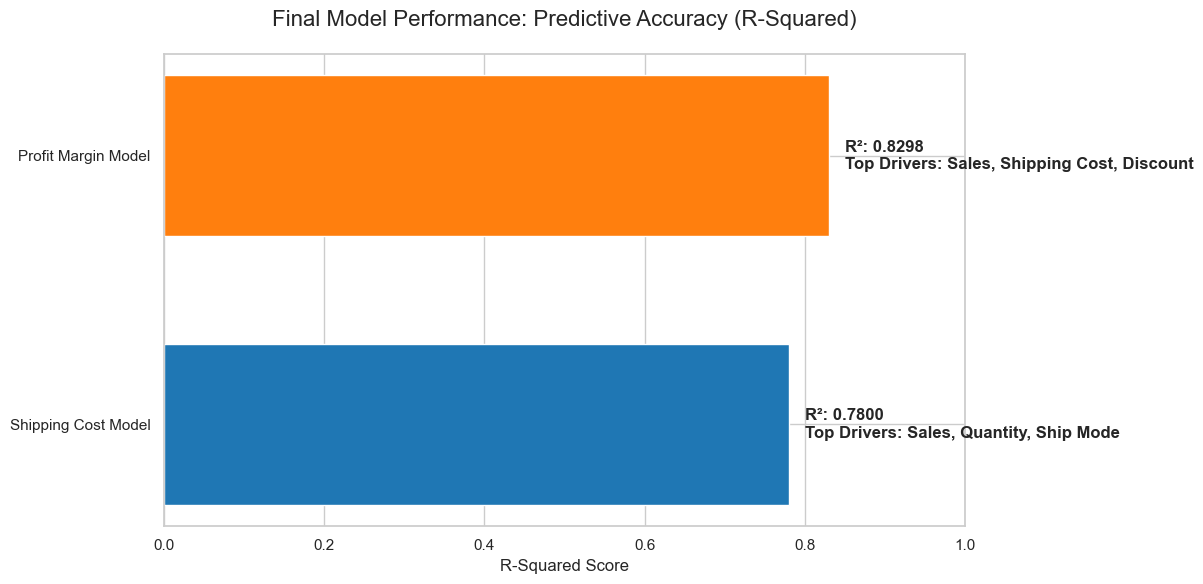

In [167]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data for the summary
models = ['Shipping Cost Model', 'Profit Margin Model']
r2_scores = [0.78, 0.8298]
top_drivers = ['Sales, Quantity, Ship Mode', 'Sales, Shipping Cost, Discount']

# Set style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))

# Create the bar chart for R2 Scores
colors = ['#1f77b4', '#ff7f0e']
bars = ax.barh(models, r2_scores, color=colors, height=0.6)

# Formatting the visual
ax.set_xlim(0, 1.0)
ax.set_title('Final Model Performance: Predictive Accuracy (R-Squared)', fontsize=16, pad=20)
ax.set_xlabel('R-Squared Score', fontsize=12)

# Adding text labels for scores and drivers
for i, bar in enumerate(bars):
    width = bar.get_width()
    ax.text(width + 0.02, bar.get_y() + bar.get_height()/2, 
            f'R²: {width:.4f}\nTop Drivers: {top_drivers[i]}', 
            va='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

                                                                __End__